### **Configuração Pasta Raiz**

In [1]:
import sys
import os

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))

# Adiciona a raiz do projeto ao path do Python para que as importações funcionem
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# print(f"Raiz do projeto definida como: {PROJECT_ROOT}")

### **Bibliotecas**

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math                                                                        # Funções matemáticas
from adjustText import adjust_text # Biblioteca opcional para textos não se sobreporem (se não tiver, o código funciona sem)
import numpy as np

### **Leitura da base de dados**

In [3]:
FILES = {
    'all_players': "data/01_final_dataset_merged.csv",
    'college_players': "data/02_college_players_dataset.csv",
    'college_players_before_2021': "data/03_college_players_before_2021_dataset.csv",
    'college_players_after_2021': "data/04_college_players_after_2021_dataset.csv",
    'college_players_after_2021_dropped': "data/05_college_players_after_2021_dropped_dataset.csv",
    'final': "data/00_final_dataset.csv"
}

In [4]:
dfs = {}

for key, filename in FILES.items():
    file_path = f'../{filename}'
    
    try:
        dfs[key] = pd.read_csv(file_path)
        
        print(f"✅ {key.ljust(15)}: Carregado ({len(dfs[key])} linhas)")
        
    except FileNotFoundError:
        print(f"❌ {key.ljust(15)}: Arquivo não encontrado em '{file_path}'")
    except Exception as e:
        print(f"❌ {key.ljust(15)}: Erro - {e}")

✅ all_players    : Carregado (1542 linhas)
✅ college_players: Carregado (1183 linhas)
✅ college_players_before_2021: Carregado (954 linhas)
✅ college_players_after_2021: Carregado (229 linhas)
✅ college_players_after_2021_dropped: Carregado (229 linhas)
✅ final          : Carregado (954 linhas)


In [5]:
df_all_players = dfs['all_players'].copy()
df_college_players = dfs['college_players'].copy()
df_final_all_colluns = dfs['college_players_before_2021'].copy()
df_final = dfs['final'].copy()

### **Todos os jogadores do draft 2000 até 2025**

In [6]:
df_all_players.head()

,player_id,player_name,draft_year,college_name,draft_pick,vorp_5y_sum,seasons_played,draft_age,true_shooting_pct,three_point_attempt_rate,...,three_point_pct,career_games,career_starts,career_minutes,career_awards_count,years_college,position,height_cm,weight_kg,mock_pick
0,martike01,Kenyon Martin,2000,Cincinnati,1,7.7,5.0,22.0,0.601,0.018,...,0.286,116.0,97.0,2900.0,1.0,4.0,Center,205.7,106.1,1.0
1,swiftst01,Stromile Swift,2000,LSU,2,2.3,5.0,20.0,0.625,0.073,...,0.280,50.0,40.0,1332.0,1.0,2.0,Forward,205.7,102.1,2.0
2,milesda01,Darius Miles,2000,NaN,3,0.0,0.0,NaN,NaN,NaN,...,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0
3,fizerma01,Marcus Fizer,2000,Iowa State,4,-2.6,5.0,21.0,0.625,0.075,...,0.357,97.0,91.0,3020.0,1.0,3.0,Forward,205.7,118.8,3.0
4,millemi01,Mike Miller,2000,Florida,5,7.1,5.0,19.0,0.581,0.378,...,0.338,65.0,56.0,1735.0,0.0,2.0,Forward,203.2,98.9,10.0


In [7]:
df_all_players.describe()

,draft_year,draft_pick,vorp_5y_sum,seasons_played,draft_age,true_shooting_pct,three_point_attempt_rate,free_throw_attempt_rate,usage_pct,offensive_win_shares,...,points,three_point_pct,career_games,career_starts,career_minutes,career_awards_count,years_college,height_cm,weight_kg,mock_pick
count,1542.000000,1542.000000,1542.000000,1542.000000,1189.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,...,1183.000000,1542.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1278.000000,1278.000000,1542.000000
mean,2012.527886,30.200389,1.102918,2.784047,20.480235,0.577995,0.276524,0.414814,24.175613,2.949873,...,19.833474,0.244438,85.655959,67.532544,2390.879966,0.301775,2.733728,198.255164,97.643505,33.488975
std,7.454569,17.168272,3.263285,2.141807,1.449714,0.046816,0.182256,0.143898,4.501575,1.325692,...,3.914552,0.185415,39.220956,34.781144,1147.608664,0.555899,1.183332,8.362395,11.356735,19.849487
min,2000.000000,1.000000,-4.100000,0.000000,18.000000,0.394000,0.000000,0.112000,11.600000,-0.600000,...,8.500000,0.000000,3.000000,0.000000,53.000000,0.000000,1.000000,173.400000,67.700000,1.000000
25%,2006.000000,15.000000,-0.200000,0.000000,19.000000,0.547000,0.114500,0.308000,20.950000,2.000000,...,17.200000,0.000000,52.500000,35.000000,1277.500000,0.000000,2.000000,193.000000,89.325000,16.000000
50%,2013.000000,30.000000,0.000000,3.000000,21.000000,0.576000,0.298000,0.396000,24.000000,2.900000,...,19.600000,0.325000,90.000000,66.000000,2360.000000,0.000000,3.000000,198.100000,96.850000,32.000000
75%,2019.000000,45.000000,0.800000,5.000000,22.000000,0.608000,0.414000,0.495500,27.300000,3.800000,...,22.450000,0.384750,123.500000,95.500000,3304.500000,1.000000,4.000000,204.500000,105.200000,53.000000
max,2025.000000,60.000000,32.000000,5.000000,26.000000,0.760000,0.811000,1.185000,39.300000,7.900000,...,34.200000,1.000000,169.000000,163.000000,5309.000000,4.000000,4.000000,222.900000,143.300000,61.000000


In [8]:
college_name = df_all_players['college_name']

In [9]:
# 1. Preparar os dados
total = len(college_name)
com_college = college_name.count()      # Conta não-nulos
sem_college = college_name.isna().sum() # Conta nulos

# Calcular porcentagens para printar (opcional)
pct_com = (com_college / total) * 100
pct_sem = (sem_college / total) * 100

In [10]:
print(f"Jogadores com College: {com_college} ({pct_com:.1f}%)")
print(f"Jogadores sem College: {sem_college} ({pct_sem:.1f}%)")

Jogadores com College: 1194 (77.4%)
Jogadores sem College: 348 (22.6%)


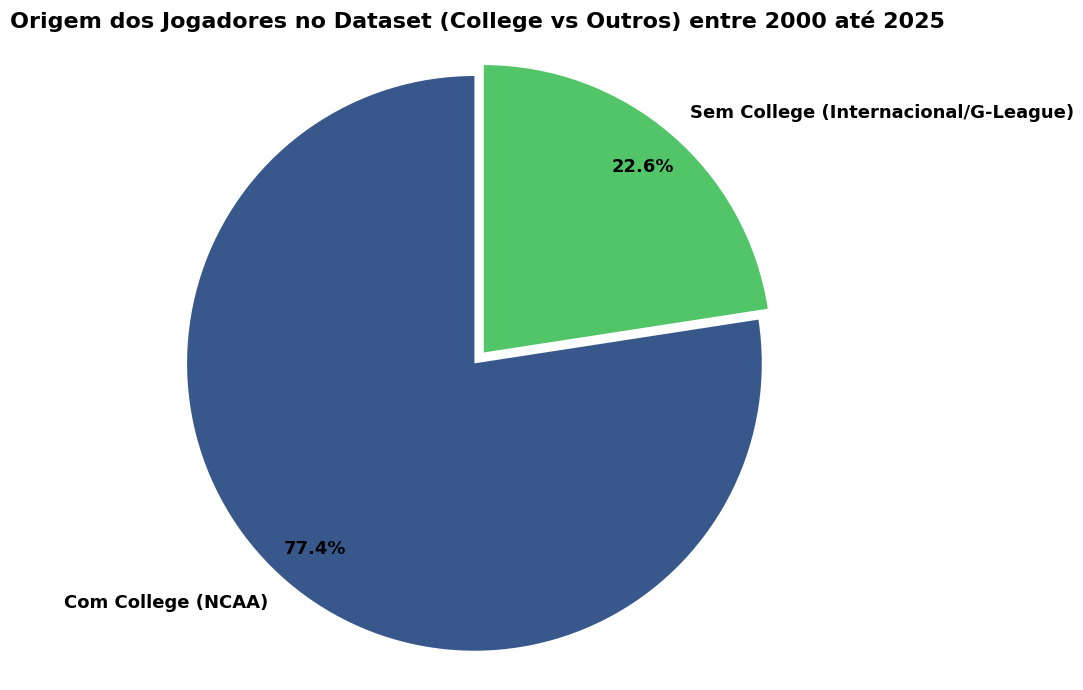

In [11]:
# 2. Configurações do Gráfico
labels = ['Com College (NCAA)', 'Sem College (Internacional/G-League)']
sizes = [com_college, sem_college]

# Usando a mesma paleta 'viridis' dos outros gráficos para consistência visual
# O [0.8] e [0.2] pegam um tom mais claro e um mais escuro da paleta
colors = [sns.color_palette('viridis', n_colors=10)[2], sns.color_palette('viridis', n_colors=10)[7]]
explode = (0.05, 0) # Destacar a fatia principal

# 3. Gerar o Gráfico
plt.figure(figsize=(10, 7))

plt.pie(sizes, 
        explode=explode, 
        labels=labels, 
        colors=colors, 
        autopct='%1.1f%%', 
        shadow=False,            # Removi a sombra para ficar "Flat Design" (mais moderno)
        startangle=90, 
        textprops={'fontsize': 13, 'weight': 'bold'}, # Fonte maior e em negrito nos números
        pctdistance=0.85         # Posiciona a % um pouco mais para a borda
       )

# Título no padrão dos anteriores (Fonte 16 e Negrito)
plt.title('Origem dos Jogadores no Dataset (College vs Outros) entre 2000 até 2025', 
          fontsize=16, 
          fontweight='bold')

plt.axis('equal') 
plt.tight_layout()
plt.show()

### **Jogadores do college draftados entre 2000 até 2020**

#### **Visulização da base**

In [12]:
df_final_all_colluns.head()

,player_id,player_name,draft_year,college_name,draft_pick,vorp_5y_sum,seasons_played,draft_age,true_shooting_pct,three_point_attempt_rate,...,career_starts,career_minutes,career_awards_count,years_college,position,height_cm,weight_kg,mock_pick,target_class,target_label
0,martike01,Kenyon Martin,2000,Cincinnati,1,7.7,5.0,22.0,0.601,0.018,...,97.0,2900.0,1.0,4.0,Center,205.7,106.1,1.0,2,Starter
1,swiftst01,Stromile Swift,2000,LSU,2,2.3,5.0,20.0,0.625,0.073,...,40.0,1332.0,1.0,2.0,Forward,205.7,102.1,2.0,1,Rotation
2,fizerma01,Marcus Fizer,2000,Iowa State,4,-2.6,5.0,21.0,0.625,0.075,...,91.0,3020.0,1.0,3.0,Forward,205.7,118.8,3.0,0,Bust
3,millemi01,Mike Miller,2000,Florida,5,7.1,5.0,19.0,0.581,0.378,...,56.0,1735.0,0.0,2.0,Forward,203.2,98.9,10.0,2,Starter
4,johnsde03,DerMarr Johnson,2000,Cincinnati,6,0.5,5.0,19.0,0.594,0.478,...,32.0,879.0,0.0,1.0,Guard,205.7,91.2,6.0,1,Rotation


In [13]:
df_final_all_colluns.describe()

,draft_year,draft_pick,vorp_5y_sum,seasons_played,draft_age,true_shooting_pct,three_point_attempt_rate,free_throw_attempt_rate,usage_pct,offensive_win_shares,...,three_point_pct,career_games,career_starts,career_minutes,career_awards_count,years_college,height_cm,weight_kg,mock_pick,target_class
count,954.000000,954.000000,954.000000,954.000000,954.000000,954.000000,954.000000,954.000000,954.000000,954.000000,...,954.000000,954.000000,954.000000,954.000000,954.000000,954.000000,954.000000,954.000000,954.000000,954.000000
mean,2010.446541,29.284067,1.719811,3.828092,20.561845,0.577232,0.261016,0.427935,24.201205,3.013836,...,0.314308,88.724319,70.395178,2488.808176,0.300839,2.829140,197.811740,97.926834,31.047170,0.723270
std,6.004001,17.113779,3.937355,1.723185,1.413045,0.045835,0.182933,0.145602,4.491005,1.324987,...,0.152329,37.500395,33.651476,1102.266151,0.548449,1.147629,8.458264,11.501604,19.209096,0.893572
min,2000.000000,1.000000,-4.100000,0.000000,18.000000,0.396000,0.000000,0.119000,12.420000,-0.600000,...,0.000000,3.000000,0.000000,53.000000,0.000000,1.000000,173.400000,67.700000,1.000000,0.000000
25%,2006.000000,14.000000,-0.300000,3.000000,19.000000,0.547000,0.081250,0.320000,21.000000,2.025000,...,0.286000,63.000000,39.000000,1604.250000,0.000000,2.000000,191.800000,89.400000,14.000000,0.000000
50%,2011.000000,29.000000,0.000000,5.000000,21.000000,0.574000,0.281500,0.407500,24.010000,3.000000,...,0.354000,95.000000,69.000000,2479.500000,0.000000,3.000000,198.100000,97.500000,30.000000,0.000000
75%,2016.000000,44.000000,2.600000,5.000000,22.000000,0.607000,0.404750,0.508000,27.275000,3.900000,...,0.398000,125.000000,97.000000,3373.750000,1.000000,4.000000,204.325000,106.075000,47.000000,1.000000
max,2020.000000,60.000000,32.000000,5.000000,26.000000,0.760000,0.811000,1.185000,39.300000,7.300000,...,1.000000,152.000000,147.000000,4887.000000,4.000000,4.000000,218.400000,137.300000,61.000000,3.000000


In [14]:
df_final_all_colluns.isna().sum()

player_id                   0
player_name                 0
draft_year                  0
college_name                0
draft_pick                  0
vorp_5y_sum                 0
seasons_played              0
draft_age                   0
true_shooting_pct           0
three_point_attempt_rate    0
free_throw_attempt_rate     0
usage_pct                   0
offensive_win_shares        0
defensive_win_shares        0
win_shares_per_40min        0
conference                  0
field_goal_attempted        0
three_pointers_made         0
three_pointers_attempted    0
effective_field_goal_pct    0
free_throw_attempted        0
free_throw_pct              0
offensive_rebounds          0
defensive_rebounds          0
total_rebounds              0
assists                     0
steals                      0
blocks                      0
turnovers                   0
personal_fouls              0
points                      0
three_point_pct             0
career_games                0
career_sta

In [52]:
cols_order = ['Bust', 'Rotation', 'Starter', 'Star']
palette_classes = {'Star': '#1f77b4', 'Starter': '#2ca02c', 'Rotation': '#ff7f0e', 'Bust': '#d62728'}
y = df_final_all_colluns['target_label']
all_players = len(df_final_all_colluns)

#### **Variavel resposta**

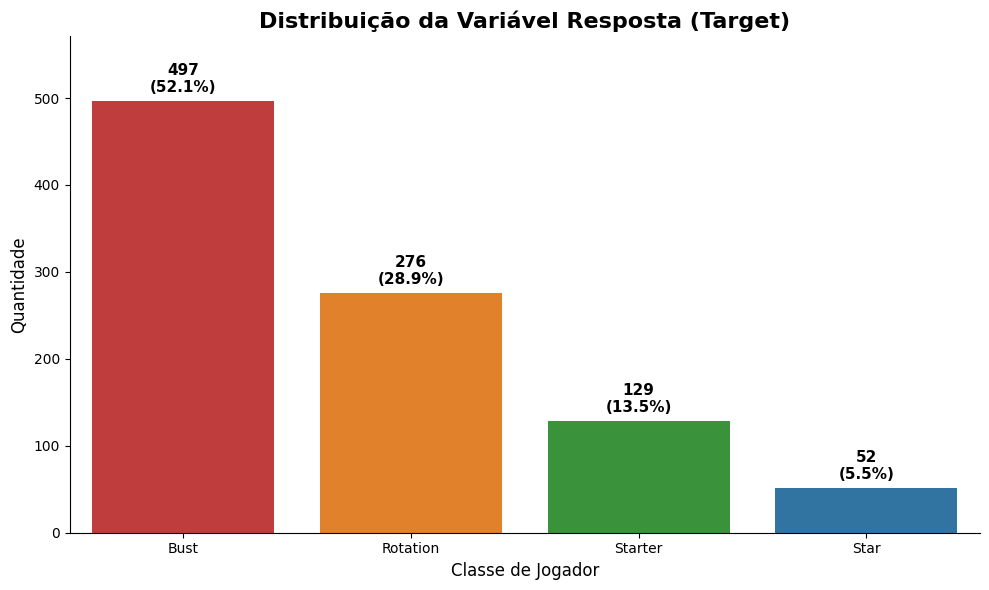

In [16]:
# Configurações
plt.figure(figsize=(10, 6))


ax = sns.countplot(
    x=y, 
    hue=y,                   # Define a cor baseada na classe
    order=cols_order, 
    palette=palette_classes, 
    legend=False             # Remove a legenda redundante
)

# Títulos
plt.title('Distribuição da Variável Resposta (Target)', fontsize=16, fontweight='bold')
plt.xlabel('Classe de Jogador', fontsize=12)
plt.ylabel('Quantidade', fontsize=12)

# Adicionar Textos (Contagem e %)
total = len(y)
for p in ax.patches:
    height = p.get_height()
    if height > 0: # Previne erro em barras vazias
        percentage = (height / total) * 100
        ax.text(p.get_x() + p.get_width() / 2., 
                height + (total * 0.01),
                f'{int(height)}\n({percentage:.1f}%)',
                ha="center", fontsize=11, fontweight='bold', color='black')

plt.ylim(0, y.value_counts().max() * 1.15)
sns.despine()
plt.tight_layout()
plt.show()

#### **Visulização da importância do ano no draft**

##### **Criando as bases**

In [17]:
vorp_by_year = df_final_all_colluns.groupby('draft_year')['vorp_5y_sum'].sum().reset_index()

In [18]:
seasons_played_by_year = df_final_all_colluns.groupby('draft_year')['seasons_played'].mean().reset_index()

In [19]:
class_dist_year = pd.crosstab(df_final_all_colluns['draft_year'], df_final_all_colluns['target_label'], normalize='index') * 100
class_dist_year = class_dist_year[cols_order]

##### **Gráfico 1: Qualidade Total (Soma do VORP)**

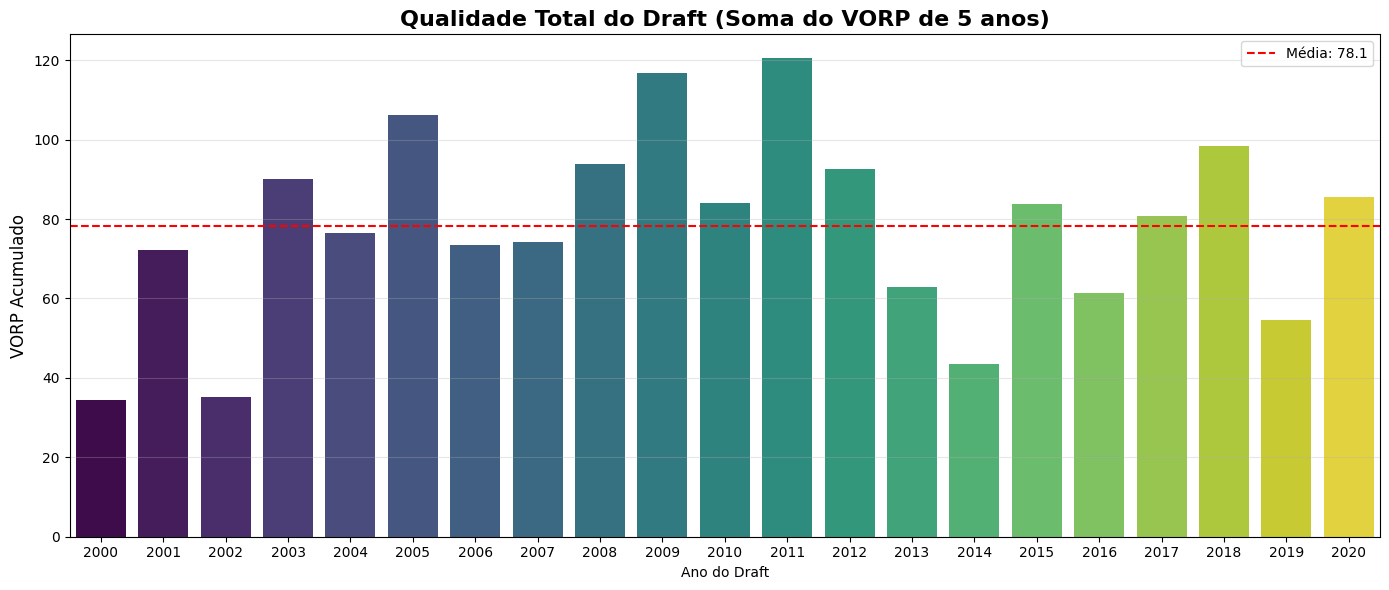

In [20]:
fig, ax = plt.subplots(1, 1, figsize=(14, 6)) 

# Gráfico 1: Qualidade Total (Soma do VORP)
sns.barplot(
    data=vorp_by_year, 
    x='draft_year', 
    y='vorp_5y_sum', 
    ax=ax, 
    palette='viridis', 
    hue='draft_year', 
    legend=False
)

ax.set_title('Qualidade Total do Draft (Soma do VORP de 5 anos)', fontsize=16, fontweight='bold')
ax.set_ylabel('VORP Acumulado', fontsize=12)
ax.set_xlabel('Ano do Draft') 
ax.grid(axis='y', alpha=0.3)

# Adicionar linha média
mean_vorp = vorp_by_year['vorp_5y_sum'].mean()
ax.axhline(mean_vorp, color='red', linestyle='--', label=f'Média: {mean_vorp:.1f}')
ax.legend()

plt.tight_layout()
plt.show()

##### **Gráfico 2: Qualidade Total (Média de Temporadas nos 5 primeiros anos)**

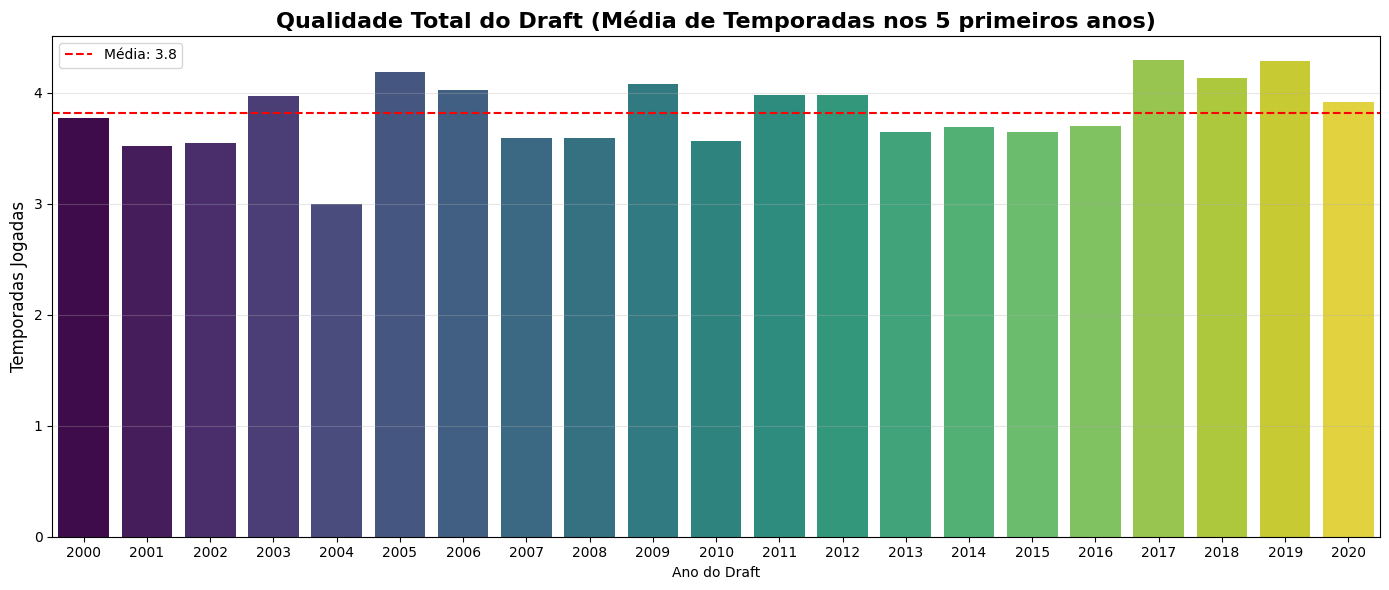

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(14, 6)) 

sns.barplot(
    data=seasons_played_by_year, 
    x='draft_year', 
    y='seasons_played', 
    ax=ax, 
    palette='viridis', 
    hue='draft_year', 
    legend=False
)

ax.set_title('Qualidade Total do Draft (Média de Temporadas nos 5 primeiros anos)', fontsize=16, fontweight='bold')
ax.set_ylabel('Temporadas Jogadas', fontsize=12)
ax.set_xlabel('Ano do Draft') 
ax.grid(axis='y', alpha=0.3)

# Adicionar linha média
mean_season = seasons_played_by_year['seasons_played'].mean()
ax.axhline(mean_season, color='red', linestyle='--', label=f'Média: {mean_season:.1f}')
ax.legend()

plt.tight_layout()
plt.show()

##### **Gráfico 3: Composição das Classes (% de Jogadores por Categoria)**

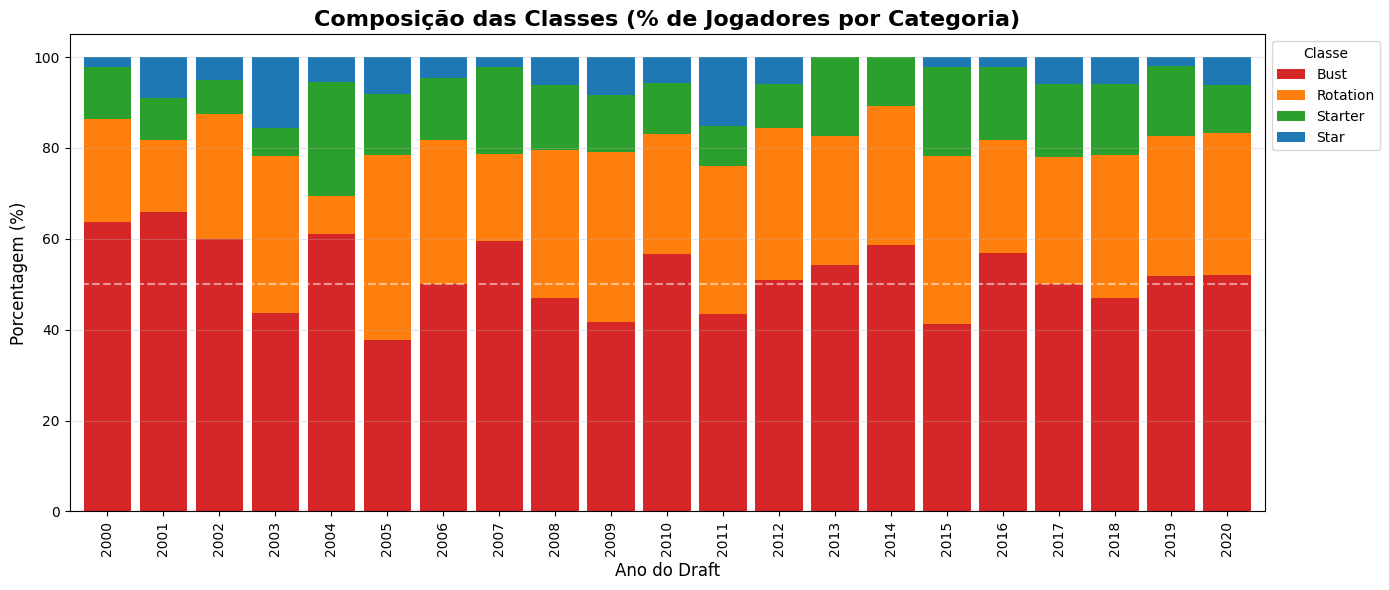

In [22]:
fig, ax = plt.subplots(1, 1, figsize=(14, 6)) 

class_dist_year.plot(kind='bar', stacked=True, ax=ax, color=palette_classes, width=0.85)

ax.set_title('Composição das Classes (% de Jogadores por Categoria)', fontsize=16, fontweight='bold')
ax.set_ylabel('Porcentagem (%)', fontsize=12)
ax.set_xlabel('Ano do Draft', fontsize=12)
ax.legend(title='Classe', bbox_to_anchor=(1.0, 1.0), loc='upper left')
ax.grid(axis='y', alpha=0.3)

# Adicionar linha de 50% para referência
ax.axhline(50, color='white', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### **Visulização por escolha do draft**

##### **Criando as bases**

In [23]:
# 1. Criar as Faixas de Draft (Binning)
# Definimos os cortes: 0 até 5, 5 até 14, 14 até 30, 30 até 60

bins = [0, 5, 14, 30, 60]
labels = ['Top 5', 'Lottery (6-14)', 'Late 1st (15-30)', '2nd Round (31-60)']

df_final_all_colluns['draft_range'] = pd.cut(df_final_all_colluns['draft_pick'], bins=bins, labels=labels)

In [24]:
# 2. Calcular a Distribuição das Classes por Faixa
range_dist = pd.crosstab(
    df_final_all_colluns['draft_range'], 
    df_final_all_colluns['target_label'], 
    normalize='index'
) * 100

# Reordenar colunas (Bust em baixo, Star no topo)
range_dist = range_dist[cols_order]

In [63]:
range_dist

target_label,Bust,Rotation,Starter,Star
draft_range,,,,
Top 5,21.428571,19.047619,33.333333,26.190476
Lottery (6-14),33.950617,33.950617,22.222222,9.876543
Late 1st (15-30),41.106719,38.339921,17.391304,3.162055
2nd Round (31-60),70.329670,23.736264,4.615385,1.318681


##### **Gráfico 1: Sucesso da escolha pelo Draft**

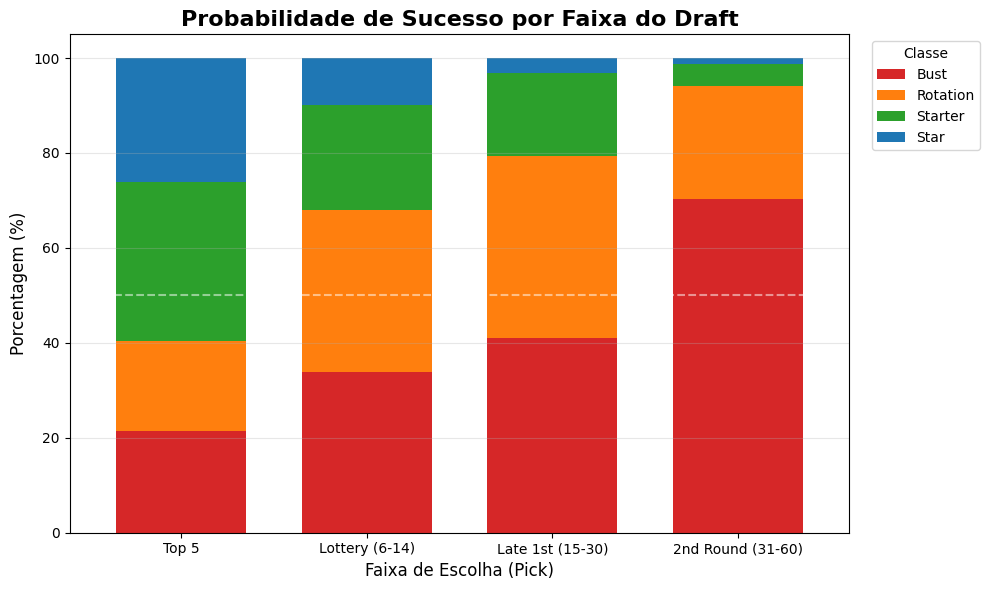

In [25]:
# 3. Plotar o Gráfico
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

range_dist.plot(kind='bar', stacked=True, ax=ax, color=palette_classes, width=0.7)

# Estética
ax.set_title('Probabilidade de Sucesso por Faixa do Draft', fontsize=16, fontweight='bold')
ax.set_ylabel('Porcentagem (%)', fontsize=12)
ax.set_xlabel('Faixa de Escolha (Pick)', fontsize=12)
ax.legend(title='Classe', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=0) # Deixar os nomes retos

# Adicionar linha de 50%
ax.axhline(50, color='white', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

##### **Gráfico 2: Mapa de valor do Draft**

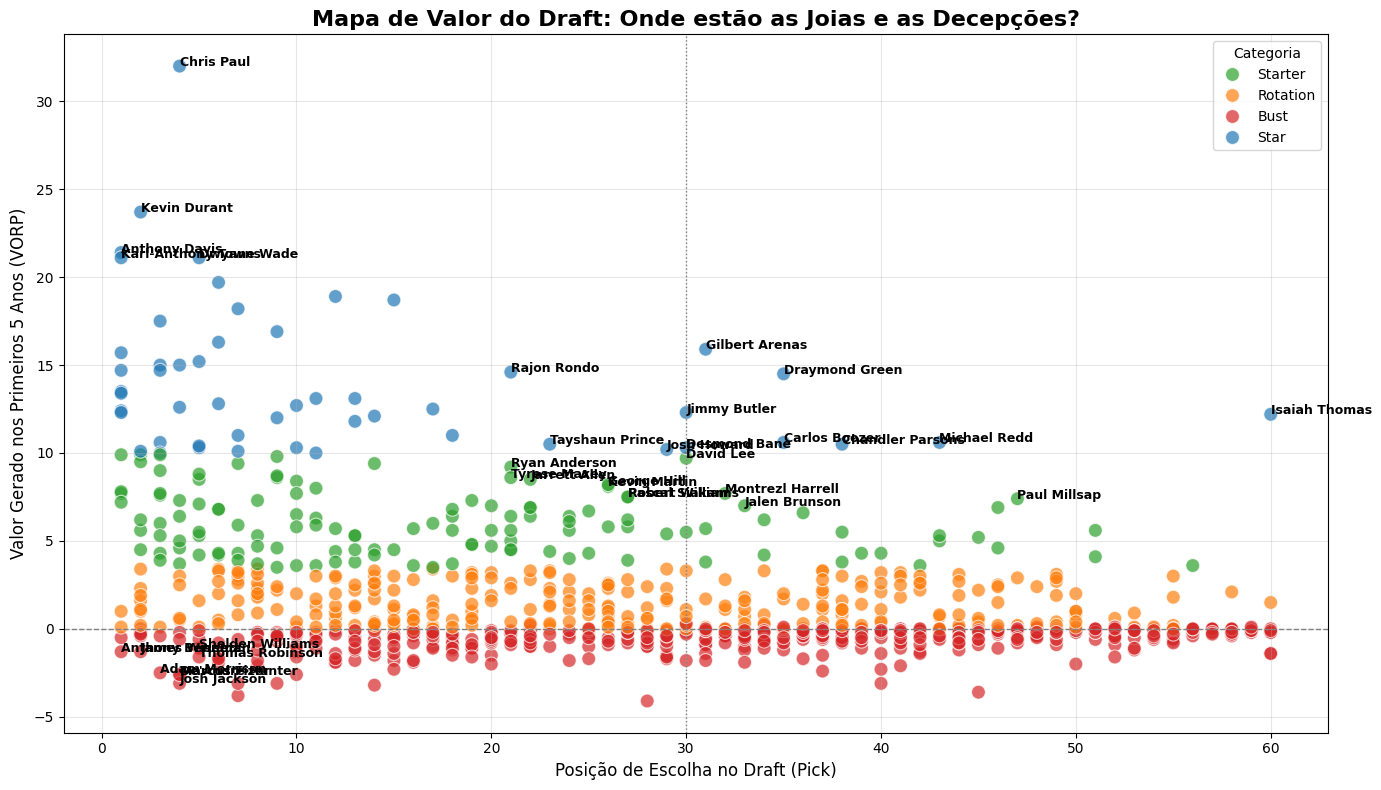

In [26]:
# 1. Configurar o Gráfico
plt.figure(figsize=(14, 8))

# 2. Scatter Plot
# X = Posição no Draft (1 a 60)
# Y = Sucesso (VORP acumulado)
# Hue = Classe (para colorir as bolinhas)
sns.scatterplot(
    data=df_final_all_colluns, 
    x='draft_pick', 
    y='vorp_5y_sum', 
    hue='target_label',
    palette=palette_classes,
    s=100, # Tamanho da bolinha
    alpha=0.7 # Transparência para ver sobreposições
)

# 3. Adicionar Linhas de Referência
plt.axhline(0, color='gray', linestyle='--', linewidth=1) # Linha do VORP 0
plt.axvline(30, color='gray', linestyle=':', linewidth=1) # Linha separando 1st e 2nd Round

# 4. ANOTAÇÃO INTELIGENTE (Colocar nomes nos destaques)
texts = []

# Regra para rotular: 
# A. Stars REAIS (VORP > 15) independente da posição
# B. "Steals" (Draft Pick > 15 E VORP > 5) -> Achados do meio/fim do draft
# C. Busts Notáveis (Draft Pick < 5 E VORP < 0) -> Decepções do topo

for i, row in df_final_all_colluns.iterrows():
    pick = row['draft_pick']
    vorp = row['vorp_5y_sum']
    name = row['player_name']
    
    # Condições para destacar o nome
    is_super_star = (vorp >= 20)
    is_steal = (pick > 20) and (vorp >= 7) # Jogador de fim de 1º round que virou Starter/Star
    is_huge_bust = (pick <= 5) and (vorp < -1) # Top 5 que atrapalhou o time
    
    if is_super_star or is_steal or is_huge_bust:
        texts.append(plt.text(pick, vorp, name, fontsize=9, weight='bold'))

# Títulos e Labels
plt.title('Mapa de Valor do Draft: Onde estão as Joias e as Decepções?', fontsize=16, fontweight='bold')
plt.xlabel('Posição de Escolha no Draft (Pick)', fontsize=12)
plt.ylabel('Valor Gerado nos Primeiros 5 Anos (VORP)', fontsize=12)
plt.legend(title='Categoria', loc='upper right')

# Inverter eixo X? Não precisa, pois 1 (Esquerda) é melhor que 60 (Direita)
# Mas se quiser ver do 60 pro 1, use: plt.gca().invert_xaxis()

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### **Visulização por College**

##### **Criando as bases**

In [55]:
df_final_all_colluns['college_name'].nunique()

162

In [27]:
top_colleges = df_final_all_colluns['college_name'].value_counts().head(15)

In [28]:
# Agrupar por College somando o VORP
vorp_by_college = df_final_all_colluns.groupby('college_name')['vorp_5y_sum'].sum().reset_index()

# Ordenar do maior para o menor e pegar o TOP 15
top_15_college_vorp = vorp_by_college.sort_values('vorp_5y_sum', ascending=False).head(15)

In [29]:
# 1. Identificar as Top 15 Universidades (por quantidade de jogadores no dataset)
# Isso cria uma lista com os nomes: ['Kentucky', 'Duke', 'UNC', ...]
top_colleges_names = top_colleges.index

# 2. Criar a Tabela Cruzada (Crosstab) Completa
class_dist_college = pd.crosstab(
    df_final_all_colluns['college_name'], 
    df_final_all_colluns['target_label'], 
    normalize='index'
) * 100

# 3. FILTRAGEM: Manter apenas os Top 15 e reordenar as colunas
class_dist_college_top = class_dist_college.loc[top_colleges_names][cols_order]

##### **Gráfico 1: Qualidade de jogadores por college**

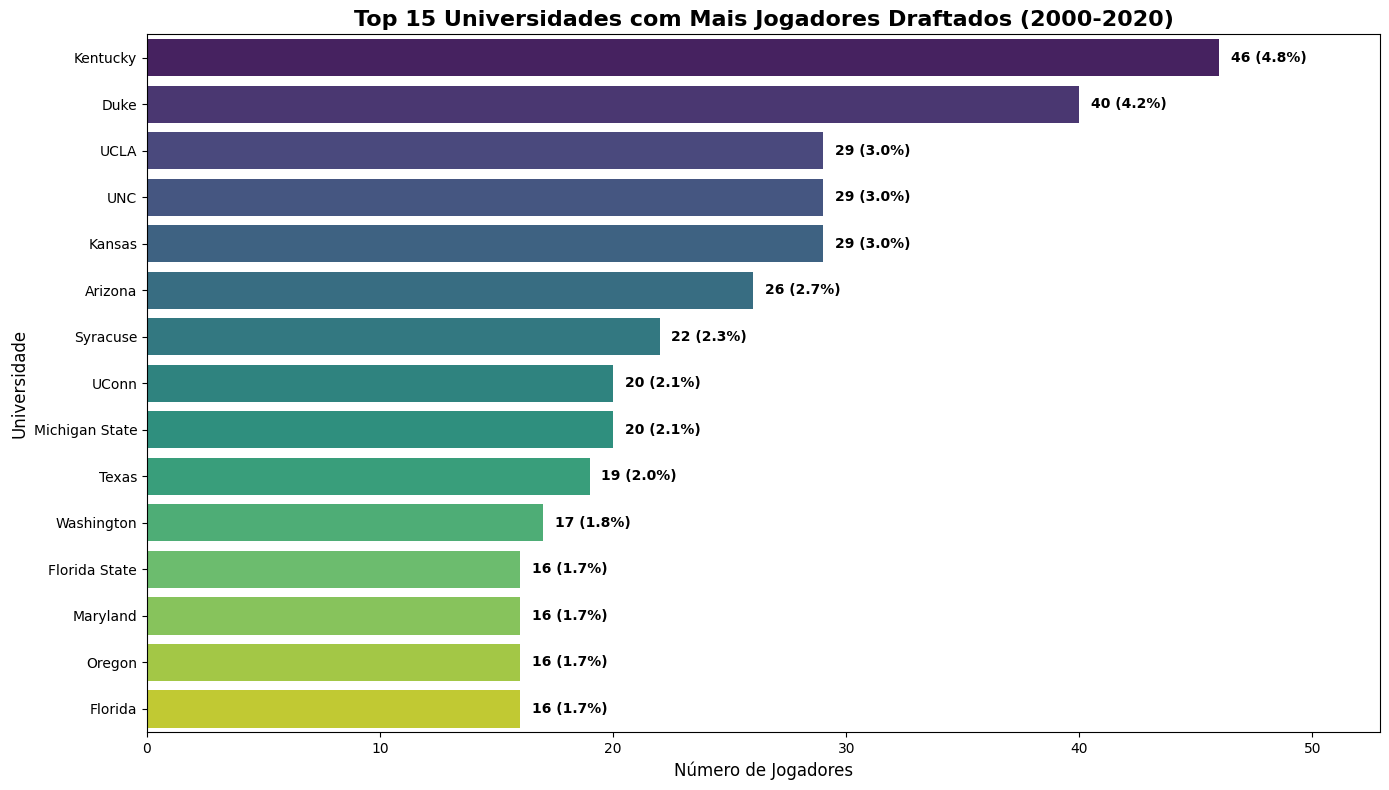

In [53]:
# Plotar
plt.figure(figsize=(14, 8)) # Aumentei um pouco a altura para ficar mais espaçado

ax = sns.barplot(
    x=top_colleges.values, 
    y=top_colleges.index, 
    hue=top_colleges.index,  
    palette='viridis', 
    legend=False            
)

plt.title('Top 15 Universidades com Mais Jogadores Draftados (2000-2020)', fontsize=16, fontweight='bold')
plt.xlabel('Número de Jogadores', fontsize=12)
plt.ylabel('Universidade', fontsize=12)

# 3. Adicionar números e porcentagens nas barras
for i, v in enumerate(top_colleges.values):
    # Cálculo da porcentagem
    pct = (v / all_players) * 100
    
    # Texto formatado: "45 (3.2%)"
    texto_label = f'{v} ({pct:.1f}%)'
    
    plt.text(
        v + 0.5,       # Posição X (um pouco à direita da barra)
        i,             # Posição Y (na linha da barra)
        texto_label, 
        color='black', 
        va='center', 
        fontweight='bold',
        fontsize=10
    )

# Aumentar um pouco o limite do eixo X para o texto não cortar na direita
plt.xlim(0, max(top_colleges.values) * 1.15)

plt.tight_layout()
plt.show()

##### **Gráfico 2: Qualidade Total (Soma do VORP)**

In [66]:
top_15_college_vorp

,college_name,vorp_5y_sum
56,Kentucky,184.5
33,Duke,108.5
130,UCLA,69.4
1,Arizona,67.6
148,Wake Forest,60.2
122,Texas,58.8
36,Florida,53.2
131,UConn,51.9
133,UNC,45.6
150,Washington,43.7


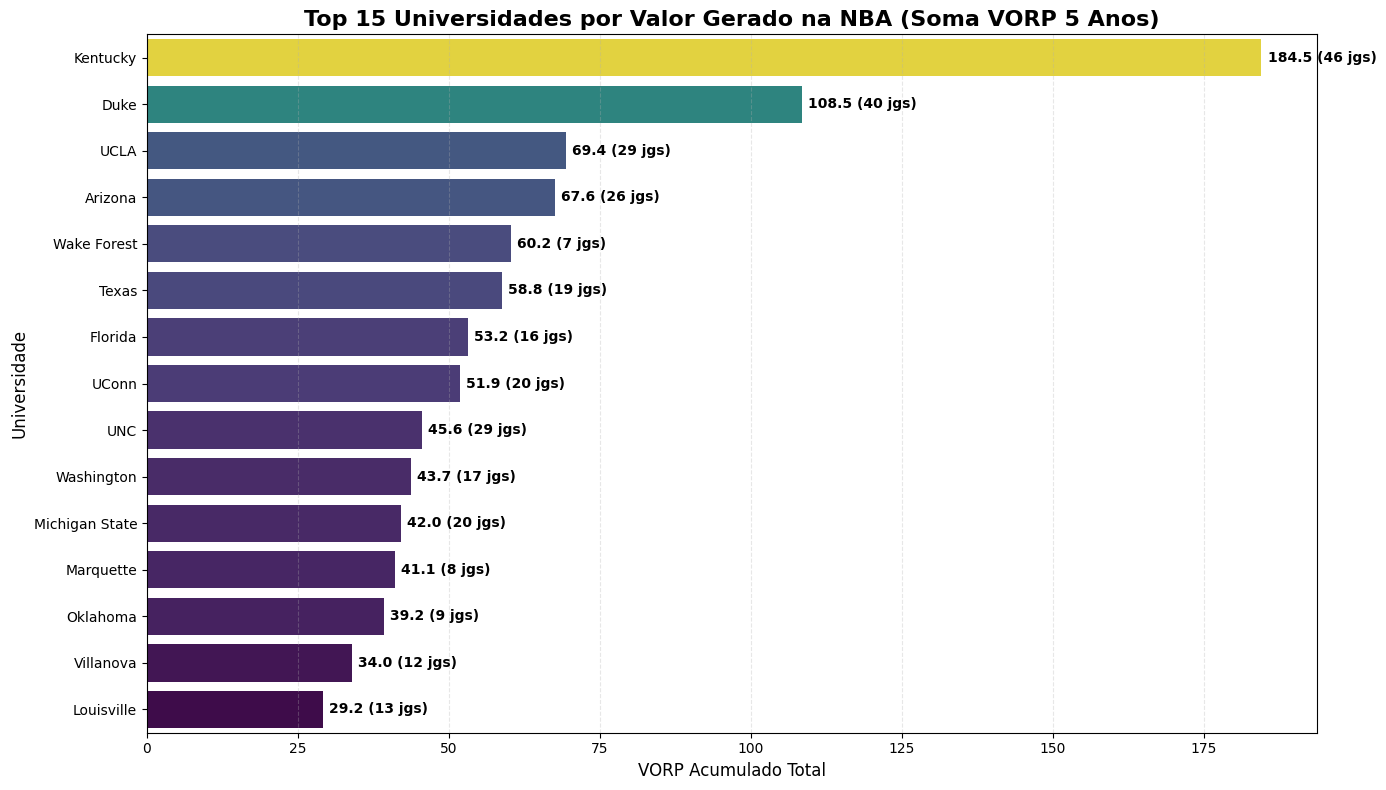

In [31]:
# 2. Gerar o Gráfico
plt.figure(figsize=(14, 8))

# Barplot Horizontal
ax = sns.barplot(
    data=top_15_college_vorp,
    x='vorp_5y_sum',
    y='college_name',
    palette='viridis',     # Mantendo o padrão visual
    hue='vorp_5y_sum',     # Gradiente de cor baseado no valor
    legend=False
)

# Estética
plt.title('Top 15 Universidades por Valor Gerado na NBA (Soma VORP 5 Anos)', fontsize=16, fontweight='bold')
plt.xlabel('VORP Acumulado Total', fontsize=12)
plt.ylabel('Universidade', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.3)

# 3. Adicionar Rótulos de Valor nas Barras
for i, v in enumerate(top_15_college_vorp['vorp_5y_sum']):
    # Pega o nome da universidade atual no loop
    college_name = top_15_college_vorp.iloc[i]['college_name']
    
    # Conta quantos jogadores essa universidade teve no dataset original
    num_players = len(df_final_all_colluns[df_final_all_colluns['college_name'] == college_name])
    
    # Monta o texto: "Valor (N jogadores)"
    label_text = f"{v:.1f} ({num_players} jgs)"
    
    # Plota o texto ao lado da barra
    ax.text(v + 1, i, label_text, va='center', fontsize=10, fontweight='bold', color='black')

plt.tight_layout()
plt.show()

In [67]:
df_final_all_colluns[df_final_all_colluns['college_name'] == 'Wake Forest']

,player_id,player_name,draft_year,college_name,draft_pick,vorp_5y_sum,seasons_played,draft_age,true_shooting_pct,three_point_attempt_rate,...,career_minutes,career_awards_count,years_college,position,height_cm,weight_kg,mock_pick,target_class,target_label,draft_range
122,songada01,Darius Songaila,2002,Wake Forest,50,0.8,5.0,23.0,0.610,0.041,...,3401.0,0.0,4.0,Forward,203.2,108.9,42.0,1,Rotation,2nd Round (31-60)
144,howarjo01,Josh Howard,2003,Wake Forest,29,10.2,5.0,22.0,0.593,0.332,...,3536.0,1.0,4.0,Forward,196.2,91.6,26.0,3,Star,Late 1st (15-30)
199,paulch01,Chris Paul,2005,Wake Forest,4,32.0,5.0,19.0,0.601,0.306,...,2110.0,1.0,2.0,Guard,182.2,80.7,4.0,3,Star,Top 5
386,johnsja01,James Johnson,2009,Wake Forest,16,2.8,5.0,21.0,0.593,0.200,...,1821.0,0.0,2.0,Forward,200.7,116.7,9.0,1,Rotation,Late 1st (15-30)
389,teaguje01,Jeff Teague,2009,Wake Forest,19,4.8,5.0,20.0,0.615,0.275,...,1883.0,1.0,2.0,Guard,183.5,79.5,19.0,2,Starter,Late 1st (15-30)
428,aminual01,Al-Farouq Aminu,2010,Wake Forest,8,2.3,5.0,19.0,0.524,0.176,...,1869.0,0.0,2.0,Forward,201.3,98.0,8.0,1,Rotation,Lottery (6-14)
770,collijo01,John Collins,2017,Wake Forest,19,7.3,5.0,19.0,0.658,0.003,...,1324.0,0.0,2.0,Forward,203.8,102.1,13.0,2,Starter,Late 1st (15-30)


##### **Gráfico 3: Composição das Classes (% de Jogadores por Categoria)**

In [64]:
class_dist_college_top

target_label,Bust,Rotation,Starter,Star
college_name,,,,
Kentucky,30.434783,30.434783,23.913043,15.217391
Duke,37.500000,37.500000,15.000000,10.000000
UCLA,34.482759,37.931034,20.689655,6.896552
UNC,41.379310,41.379310,13.793103,3.448276
Kansas,48.275862,37.931034,10.344828,3.448276
Arizona,42.307692,34.615385,11.538462,11.538462
Syracuse,68.181818,27.272727,0.000000,4.545455
UConn,45.000000,25.000000,20.000000,10.000000
Michigan State,50.000000,25.000000,15.000000,10.000000


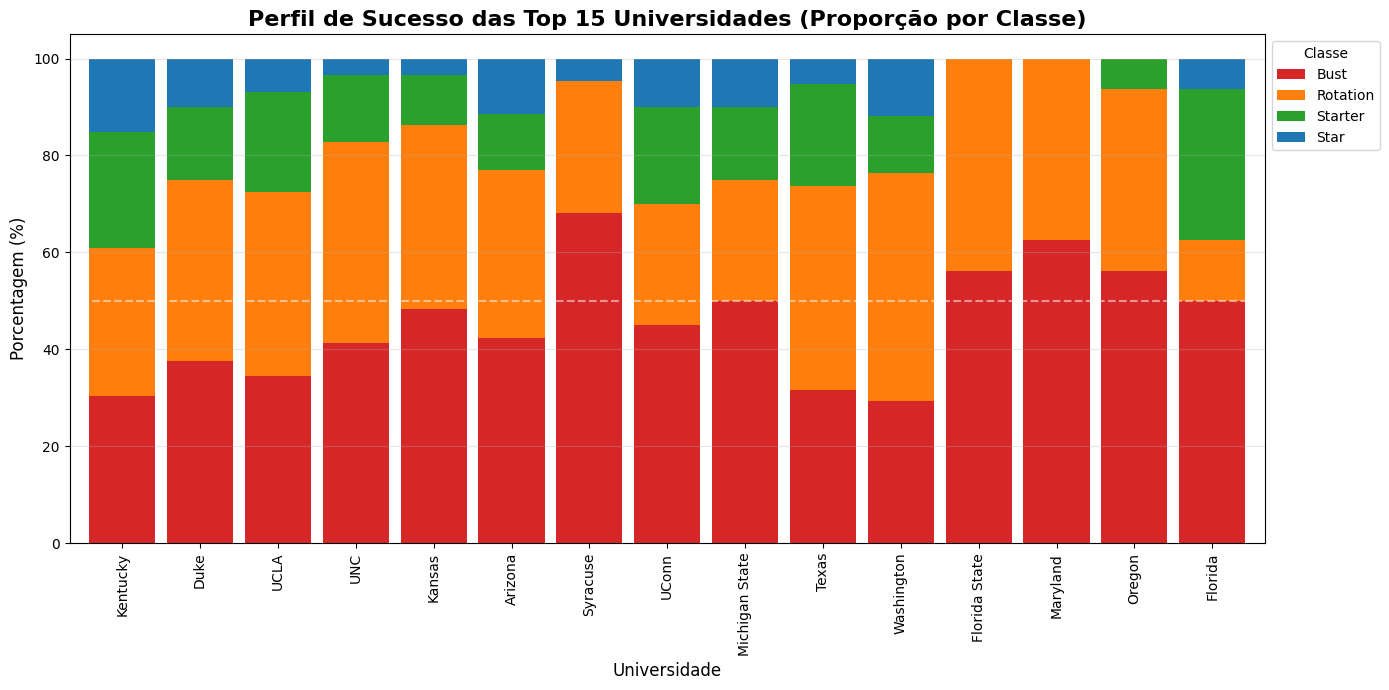

In [32]:
#  Plotar
fig, ax = plt.subplots(1, 1, figsize=(14, 7)) 

class_dist_college_top.plot(kind='bar', stacked=True, ax=ax, color=palette_classes, width=0.85)

# Estética
ax.set_title('Perfil de Sucesso das Top 15 Universidades (Proporção por Classe)', fontsize=16, fontweight='bold')
ax.set_ylabel('Porcentagem (%)', fontsize=12)
ax.set_xlabel('Universidade', fontsize=12) # Corrigido de "Ano do Draft" para "Universidade"
ax.legend(title='Classe', bbox_to_anchor=(1.0, 1.0), loc='upper left')
ax.grid(axis='y', alpha=0.3)

# Linha de referência visual (50%)
ax.axhline(50, color='white', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### **Visulização por Conference**

##### **Criando as bases**

In [56]:
df_final_all_colluns['conference'].nunique()

30

In [33]:
top_conferences = df_final_all_colluns['conference'].value_counts().head(15)

In [34]:
# Agrupar por Conference somando o VORP
vorp_by_conference = df_final_all_colluns.groupby('conference')['vorp_5y_sum'].sum().reset_index()

# Ordenar do maior para o menor e pegar o TOP 15
top_15_conference_vorp = vorp_by_conference.sort_values('vorp_5y_sum', ascending=False).head(15)

In [35]:
# 1. Identificar as Top 15 Conferences (por quantidade de jogadores no dataset)
top_conferences_names = top_conferences.index

# 2. Criar a Tabela Cruzada (Crosstab) Completa
class_dist_conference = pd.crosstab(
    df_final_all_colluns['conference'], 
    df_final_all_colluns['target_label'], 
    normalize='index'
) * 100

# 3. FILTRAGEM: Manter apenas os Top 15 e reordenar as colunas
class_dist_conference_top = class_dist_conference.loc[top_conferences_names][cols_order]

##### **Gráfico 1: Qualidade de jogadores por conference**

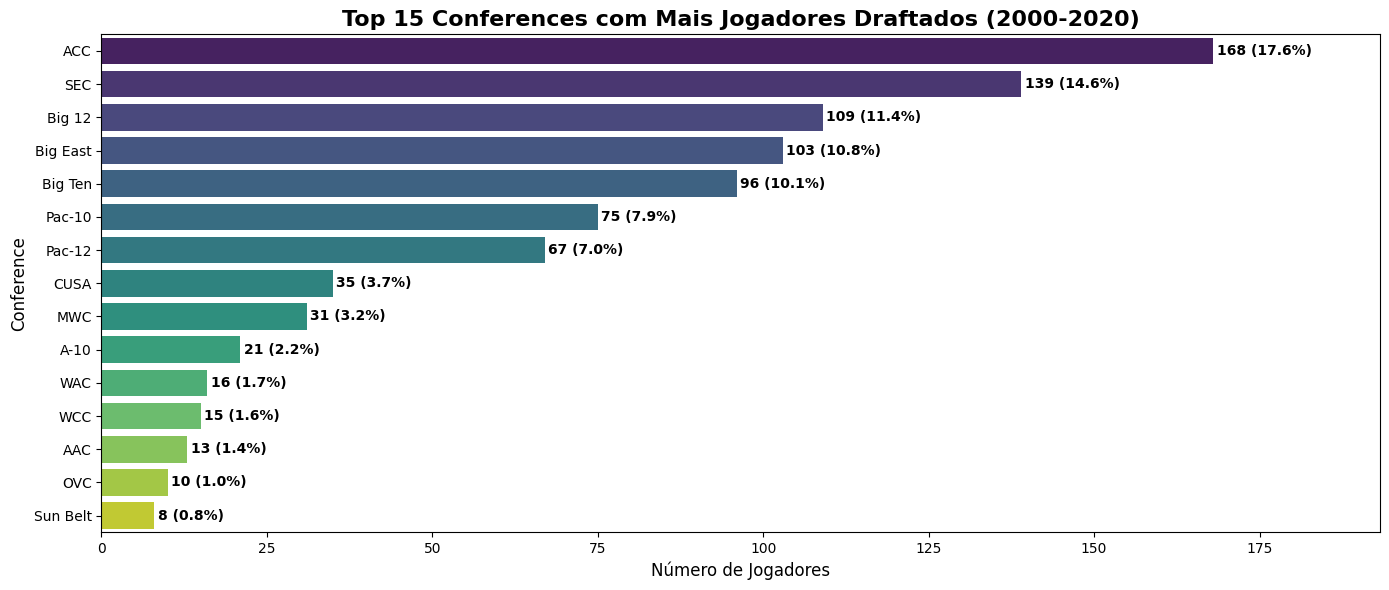

In [57]:
# Plotar
plt.figure(figsize=(14, 6))

sns.barplot(
    x=top_conferences.values, 
    y=top_conferences.index, 
    hue=top_conferences.index,  
    palette='viridis', 
    legend=False            
)

plt.title('Top 15 Conferences com Mais Jogadores Draftados (2000-2020)', fontsize=16, fontweight='bold')
plt.xlabel('Número de Jogadores', fontsize=12)
plt.ylabel('Conference', fontsize=12)

# Adicionar números nas barras
for i, v in enumerate(top_conferences.values):
    # Cálculo da porcentagem
    pct = (v / all_players) * 100
    
    # Texto formatado: "45 (3.2%)"
    texto_label = f'{v} ({pct:.1f}%)'
    
    plt.text(
        v + 0.5,       # Posição X (um pouco à direita da barra)
        i,             # Posição Y (na linha da barra)
        texto_label, 
        color='black', 
        va='center', 
        fontweight='bold',
        fontsize=10
    )

# Aumentar um pouco o limite do eixo X para o texto não cortar na direita
plt.xlim(0, max(top_conferences.values) * 1.15)

plt.tight_layout()
plt.show()

##### **Gráfico 2: Qualidade Total (Soma do VORP)**

In [68]:
top_15_conference_vorp

,conference,vorp_5y_sum
23,SEC,332.1
2,ACC,289.2
20,Pac-10,212.4
4,Big 12,161.1
5,Big East,156.7
7,Big Ten,135.3
21,Pac-12,84.9
10,CUSA,62.2
17,MWC,33.5
28,WAC,30.2


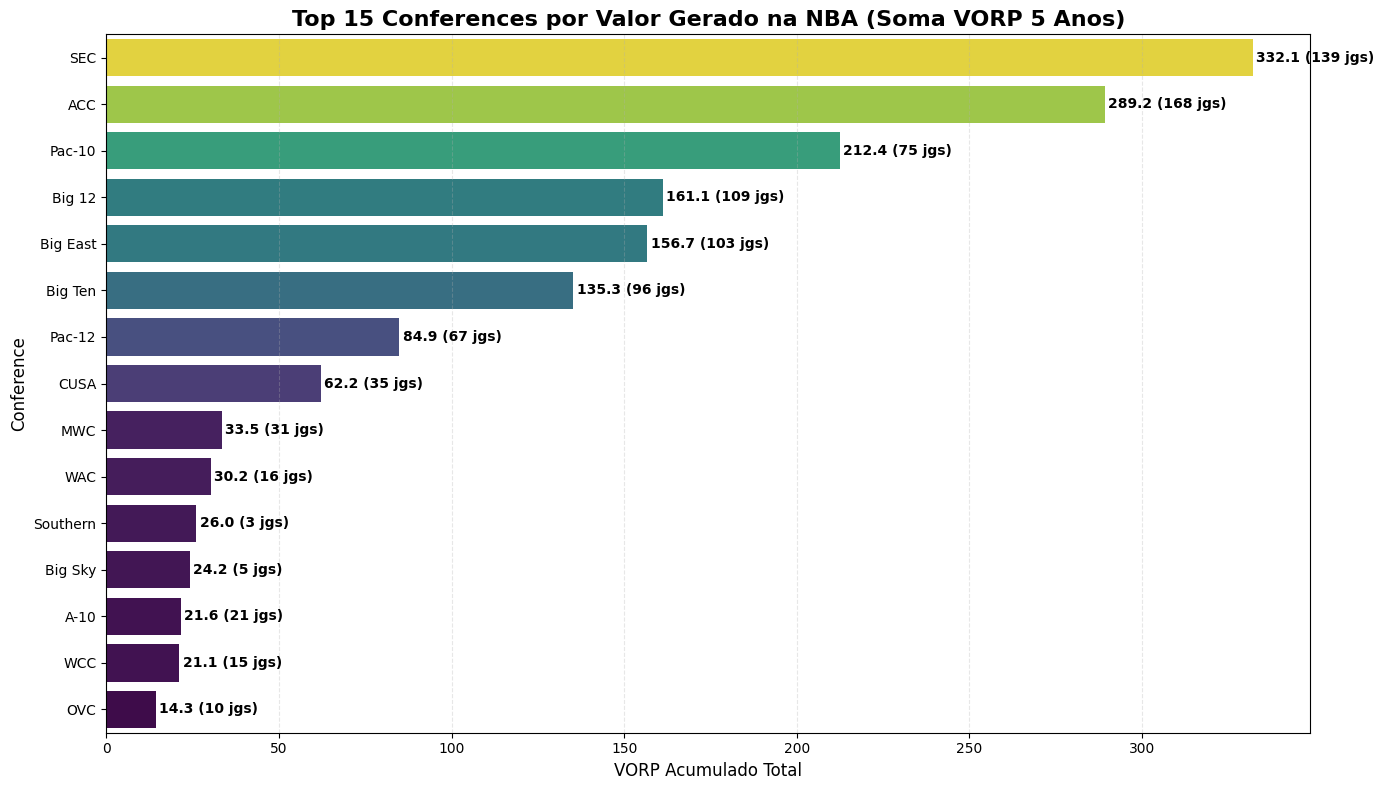

In [37]:
# 2. Gerar o Gráfico
plt.figure(figsize=(14, 8))

# Barplot Horizontal
ax = sns.barplot(
    data=top_15_conference_vorp,
    x='vorp_5y_sum',
    y='conference',
    palette='viridis',     # Mantendo o padrão visual
    hue='vorp_5y_sum',     # Gradiente de cor baseado no valor
    legend=False
)

# Estética
plt.title('Top 15 Conferences por Valor Gerado na NBA (Soma VORP 5 Anos)', fontsize=16, fontweight='bold')
plt.xlabel('VORP Acumulado Total', fontsize=12)
plt.ylabel('Conference', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.3)

# 3. Adicionar Rótulos de Valor nas Barras
for i, v in enumerate(top_15_conference_vorp['vorp_5y_sum']):
    # Pega o nome da conference atual no loop
    conference_name = top_15_conference_vorp.iloc[i]['conference']
    
    # Conta quantos jogadores essa conference teve no dataset original
    num_players = len(df_final_all_colluns[df_final_all_colluns['conference'] == conference_name])
    
    # Monta o texto: "Valor (N jogadores)"
    label_text = f"{v:.1f} ({num_players} jgs)"
    
    # Plota o texto ao lado da barra
    ax.text(v + 1, i, label_text, va='center', fontsize=10, fontweight='bold', color='black')

plt.tight_layout()
plt.show()

##### **Gráfico 3: Composição das Classes (% de Jogadores por Categoria)**

In [69]:
class_dist_conference_top

target_label,Bust,Rotation,Starter,Star
conference,,,,
ACC,48.214286,35.119048,11.309524,5.357143
SEC,46.043165,26.618705,20.143885,7.194245
Big 12,54.128440,30.275229,10.091743,5.504587
Big East,54.368932,29.126214,10.679612,5.825243
Big Ten,56.250000,27.083333,12.500000,4.166667
Pac-10,38.666667,36.000000,13.333333,12.000000
Pac-12,44.776119,34.328358,20.895522,0.000000
CUSA,54.285714,28.571429,11.428571,5.714286
MWC,77.419355,9.677419,6.451613,6.451613


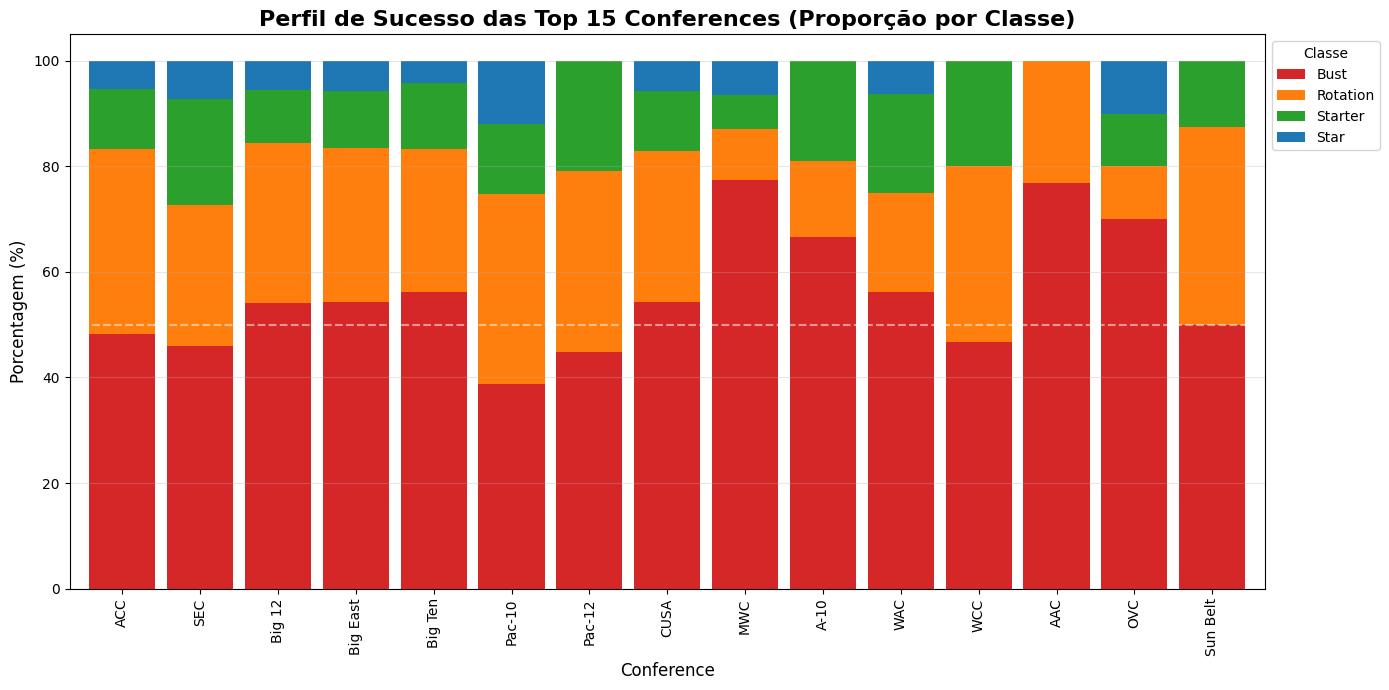

In [38]:
#  Plotar
fig, ax = plt.subplots(1, 1, figsize=(14, 7)) 

class_dist_conference_top.plot(kind='bar', stacked=True, ax=ax, color=palette_classes, width=0.85)

# Estética
ax.set_title('Perfil de Sucesso das Top 15 Conferences (Proporção por Classe)', fontsize=16, fontweight='bold')
ax.set_ylabel('Porcentagem (%)', fontsize=12)
ax.set_xlabel('Conference', fontsize=12) # Corrigido de "Ano do Draft" para ""
ax.legend(title='Classe', bbox_to_anchor=(1.0, 1.0), loc='upper left')
ax.grid(axis='y', alpha=0.3)

# Linha de referência visual (50%)
ax.axhline(50, color='white', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### **Visulização por Posição**

##### **Criando as bases**

In [39]:
top_position = df_final_all_colluns['position'].value_counts().head(15)

In [40]:
# Agrupar por Position somando o VORP
vorp_by_position = df_final_all_colluns.groupby('position')['vorp_5y_sum'].sum().reset_index().sort_values('vorp_5y_sum', ascending=False)

In [41]:
# 1. Identificar as Top 15 position (por quantidade de jogadores no dataset)
top_position_names = top_position.index

# 2. Criar a Tabela Cruzada (Crosstab) Completa
class_dist_position = pd.crosstab(
    df_final_all_colluns['position'], 
    df_final_all_colluns['target_label'], 
    normalize='index'
) * 100

# 3. FILTRAGEM: Manter apenas os Top 15 e reordenar as colunas
class_dist_position_top = class_dist_position.loc[top_position_names][cols_order]

##### **Gráfico 1: Qualidade de jogadores por posição**

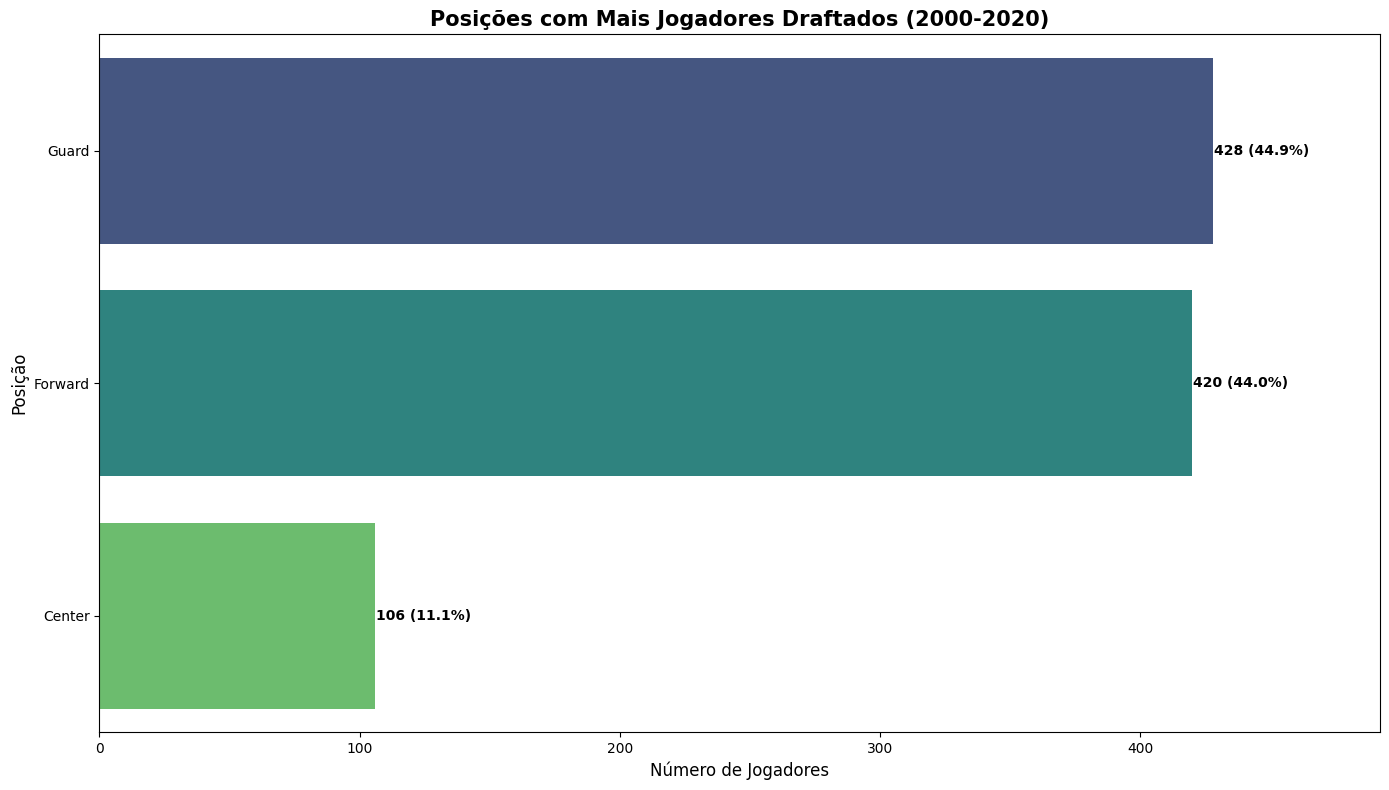

In [58]:
# Plotar
plt.figure(figsize=(14, 8)) # Aumentei um pouco a altura para ficar mais espaçado

sns.barplot(
    x=top_position.values, 
    y=top_position.index, 
    hue=top_position.index,  
    palette='viridis', 
    legend=False            
)

plt.title('Posições com Mais Jogadores Draftados (2000-2020)', fontsize=15, fontweight='bold')
plt.xlabel('Número de Jogadores', fontsize=12)
plt.ylabel('Posição', fontsize=12)

# 3. Adicionar números e porcentagens nas barras
for i, v in enumerate(top_position.values):
    # Cálculo da porcentagem
    pct = (v / all_players) * 100
    
    # Texto formatado: "45 (3.2%)"
    texto_label = f'{v} ({pct:.1f}%)'
    
    plt.text(
        v + 0.5,       # Posição X (um pouco à direita da barra)
        i,             # Posição Y (na linha da barra)
        texto_label, 
        color='black', 
        va='center', 
        fontweight='bold',
        fontsize=10
    )

# Aumentar um pouco o limite do eixo X para o texto não cortar na direita
plt.xlim(0, max(top_position.values) * 1.15)

plt.tight_layout()
plt.show()

##### **Gráfico 2: Qualidade Total (Soma do VORP)**

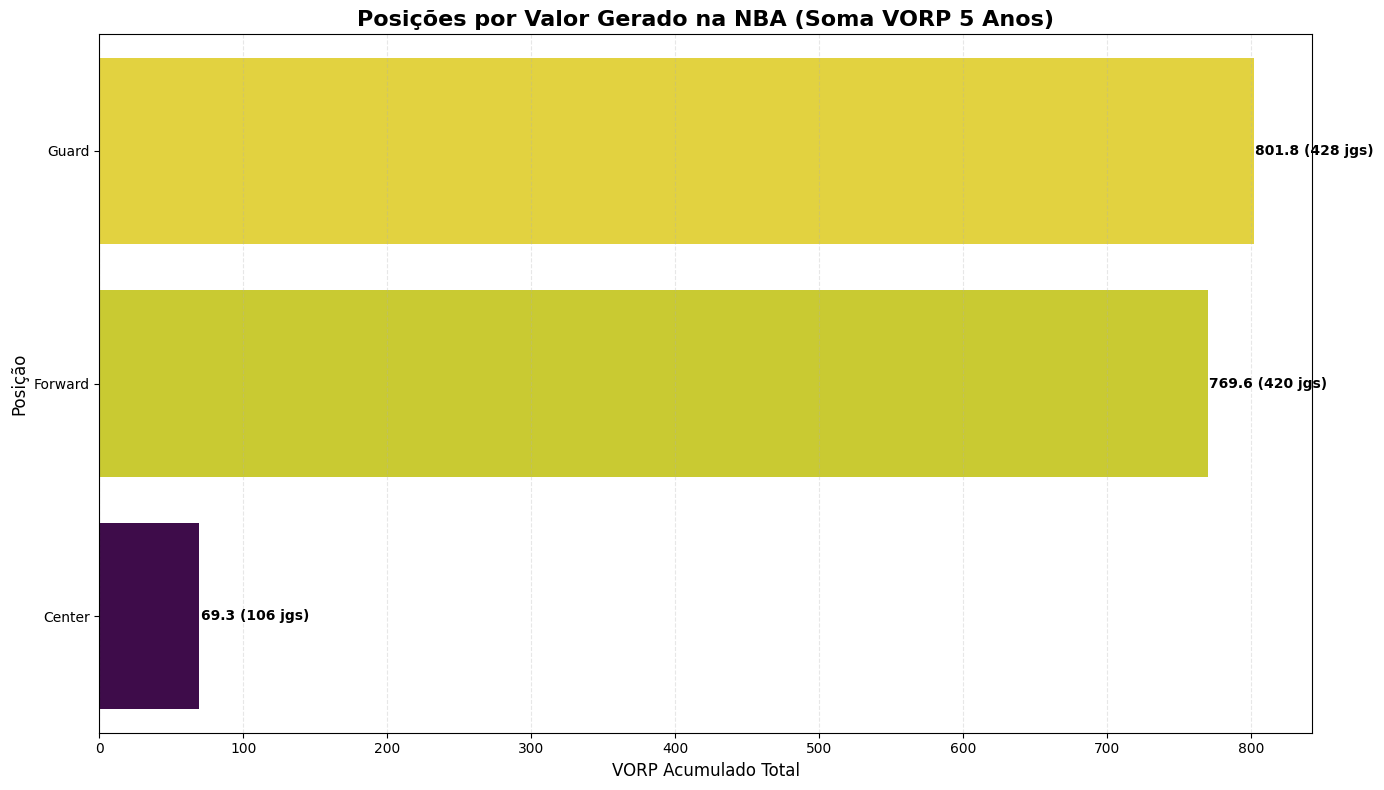

In [43]:
# 2. Gerar o Gráfico
plt.figure(figsize=(14, 8))

# Barplot Horizontal
ax = sns.barplot(
    data=vorp_by_position,
    x='vorp_5y_sum',
    y='position',
    palette='viridis',     # Mantendo o padrão visual
    hue='vorp_5y_sum',     # Gradiente de cor baseado no valor
    legend=False
)

# Estética
plt.title('Posições por Valor Gerado na NBA (Soma VORP 5 Anos)', fontsize=16, fontweight='bold')
plt.xlabel('VORP Acumulado Total', fontsize=12)
plt.ylabel('Posição', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.3)

# 3. Adicionar Rótulos de Valor nas Barras
for i, v in enumerate(vorp_by_position['vorp_5y_sum']):
    # Pega o nome da posição atual no loop
    position_name = vorp_by_position.iloc[i]['position']
    
    # Conta quantos jogadores essa posição teve no dataset original
    num_players = len(df_final_all_colluns[df_final_all_colluns['position'] == position_name])
    
    # Monta o texto: "Valor (N jogadores)"
    label_text = f"{v:.1f} ({num_players} jgs)"
    
    # Plota o texto ao lado da barra
    ax.text(v + 1, i, label_text, va='center', fontsize=10, fontweight='bold', color='black')

plt.tight_layout()
plt.show()

##### **Gráfico 3: Composição das Classes (% de Jogadores por Categoria)**

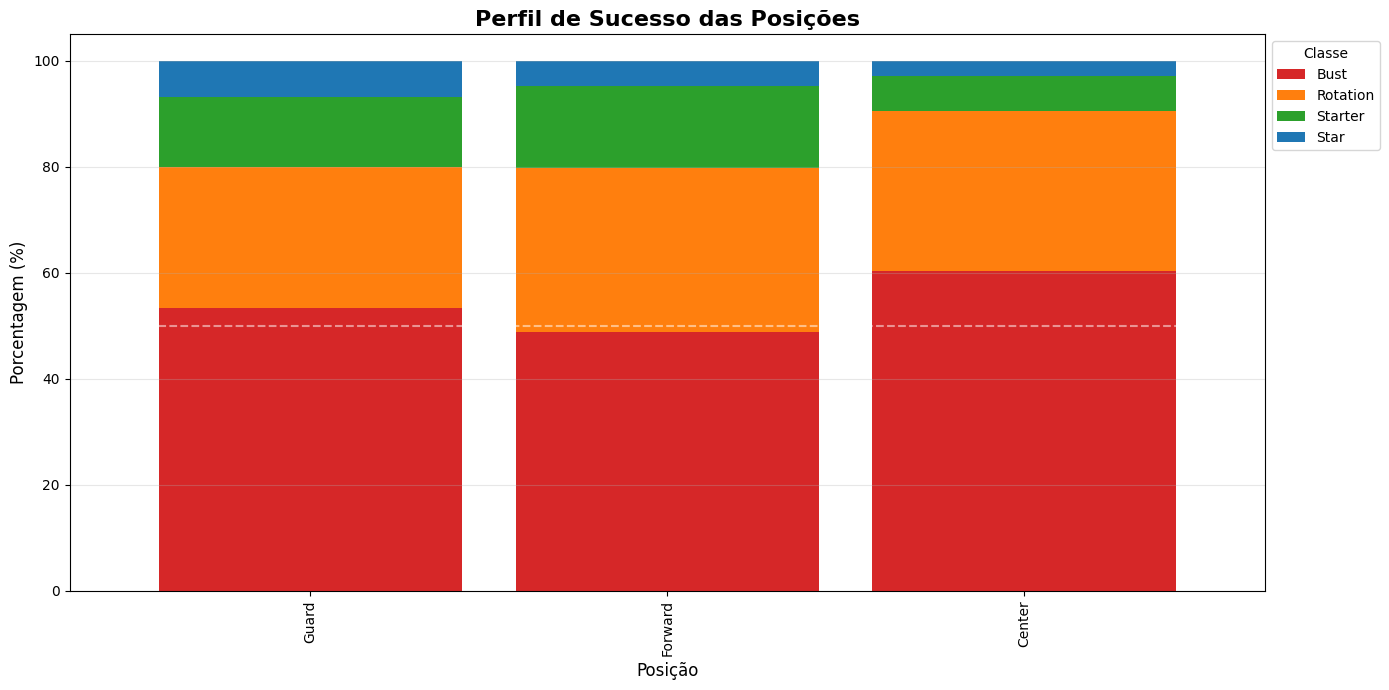

In [44]:
#  Plotar
fig, ax = plt.subplots(1, 1, figsize=(14, 7)) 

class_dist_position_top.plot(kind='bar', stacked=True, ax=ax, color=palette_classes, width=0.85)

# Estética
ax.set_title('Perfil de Sucesso das Posições', fontsize=16, fontweight='bold')
ax.set_ylabel('Porcentagem (%)', fontsize=12)
ax.set_xlabel('Posição', fontsize=12) 
ax.legend(title='Classe', bbox_to_anchor=(1.0, 1.0), loc='upper left')
ax.grid(axis='y', alpha=0.3)

# Linha de referência visual (50%)
ax.axhline(50, color='white', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### **Visualização variáveis quantitativas**

##### **Configurar Base**

In [61]:
quantitativas_features = [
    # --- Informações Físicas e do Draft ---
    'draft_year', 
    'draft_age', 
    'years_college', 
    'mock_pick',        # Expectativa do mercado antes do draft
    'height_cm', 
    'weight_kg',

    # --- Estatísticas Avançadas (Eficiência) ---
    'true_shooting_pct', 
    'effective_field_goal_pct', 
    'usage_pct',
    'offensive_win_shares', 
    'defensive_win_shares', 
    'win_shares_per_40min',
    'three_point_attempt_rate', 
    'free_throw_attempt_rate',

    # --- Estatísticas de Arremesso (Volume e Precisão) ---
    'field_goal_attempted', 
    'three_pointers_made', 
    'three_pointers_attempted', 
    'three_point_pct',
    'free_throw_attempted', 
    'free_throw_pct',

    # --- Estatísticas Tradicionais (Médias por Jogo) ---
    'points', 
    'assists', 
    'total_rebounds', 
    'offensive_rebounds', 
    'defensive_rebounds',
    'steals', 
    'blocks', 
    'turnovers', 
    'personal_fouls',

    # --- Experiência no College (Acumulados) ---
    'career_games', 
    'career_starts', 
    'career_minutes', 
    'career_awards_count'
]

quantitativas_features_eda = [
    'win_shares_per_40min', 'true_shooting_pct',
    'points', 'total_rebounds', 'assists',
    'steals', 'blocks', 'draft_age', 'three_point_attempt_rate'
]

##### **Gráfico 1: Análise de relação com a resposta**

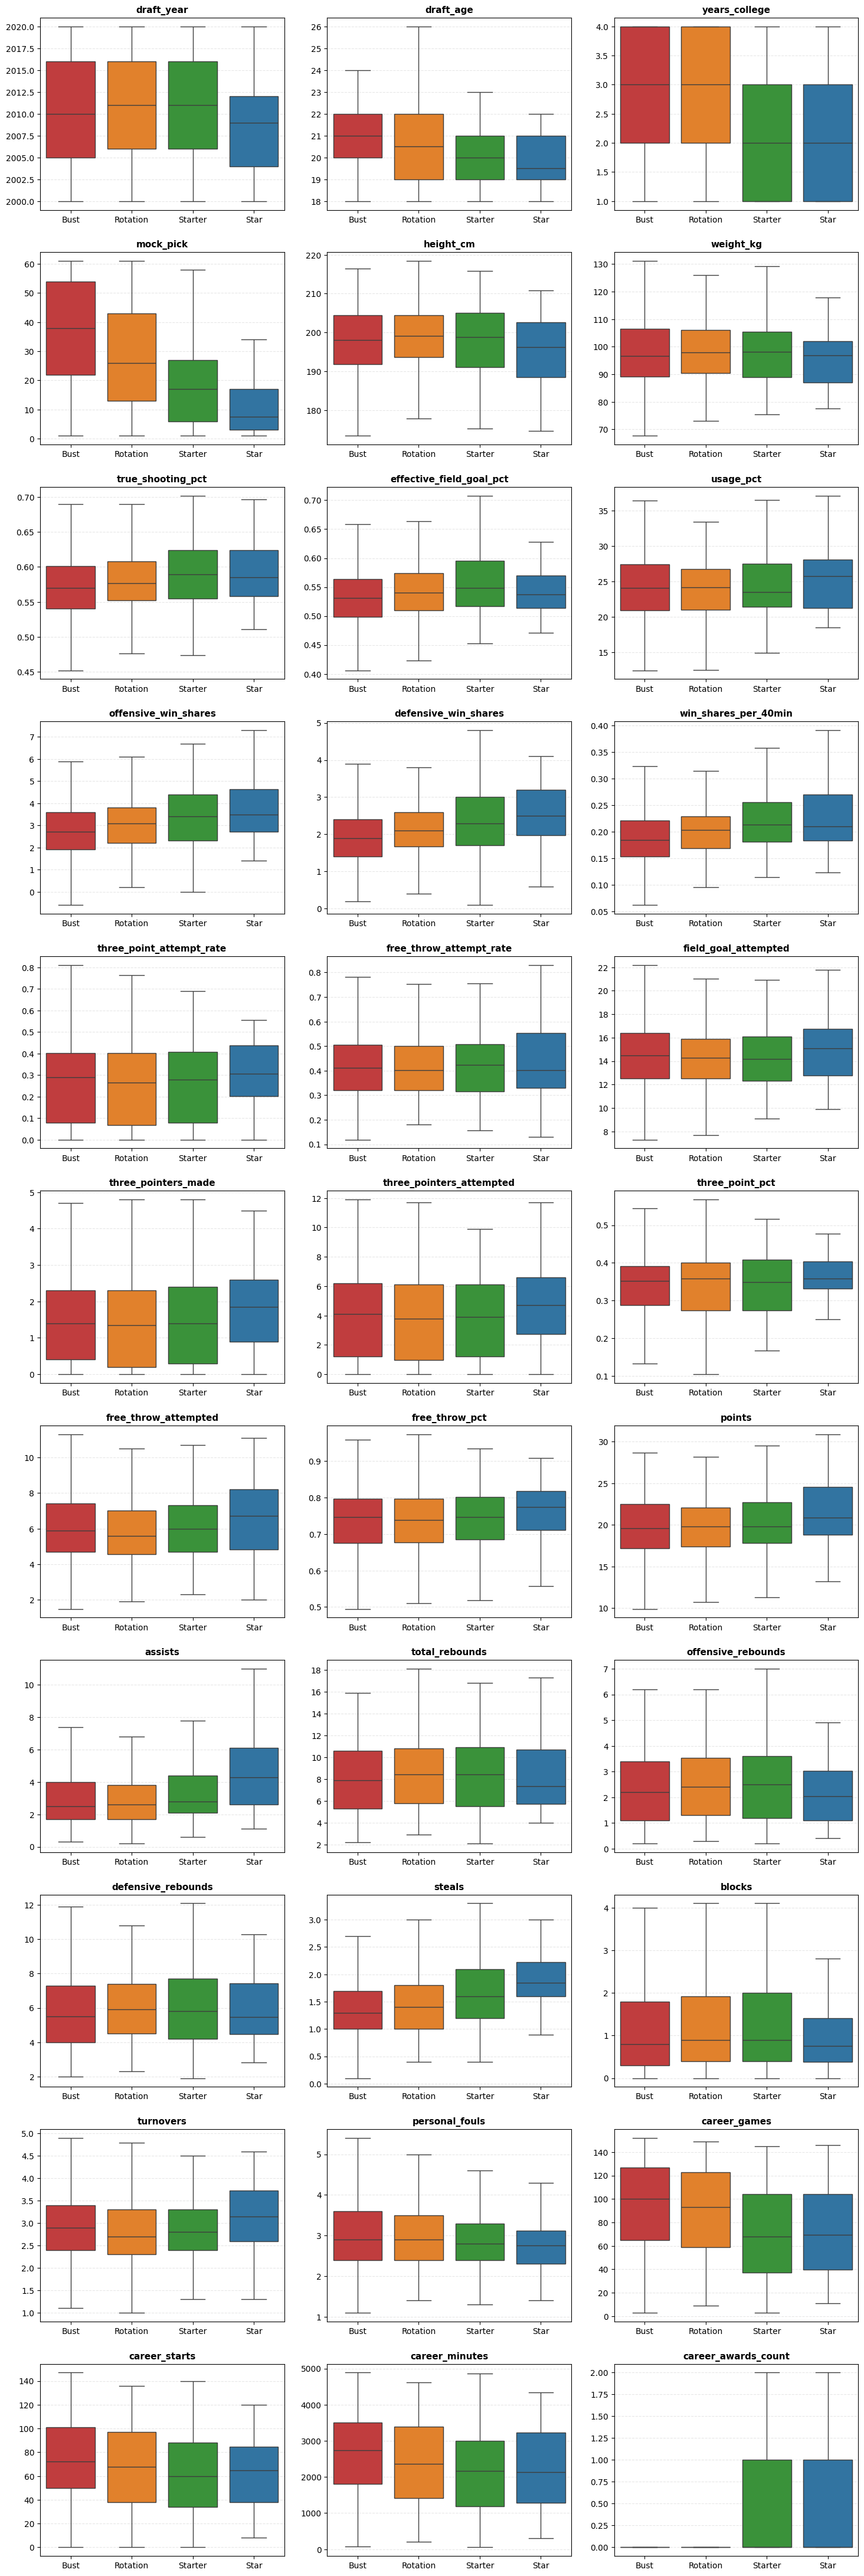

In [46]:
if quantitativas_features:
    n = len(quantitativas_features)
    ncols = 3
    nrows = math.ceil(n / ncols)
    
    fig, axes = plt.subplots(nrows=nrows, 
                             ncols=ncols, 
                             figsize=(15, 4 * nrows))
    
    # Garante que axes seja sempre uma lista
    if n == 1: axes = [axes]
    else: axes = axes.flatten()

    for i, var in enumerate(quantitativas_features):
        sns.boxplot(
            y=df_final_all_colluns[var], 
            x=y,                  # Seu target
            hue=y,                # <--- CORREÇÃO DO AVISO: hue deve ser igual ao x
            ax=axes[i],
            order=cols_order,
            palette=palette_classes,
            showfliers=False,
            legend=False          # <--- CORREÇÃO: Remove a legenda duplicada
        )
        
        # Estética
        axes[i].set_title(f'{var}', fontweight='bold', fontsize=11)
        axes[i].set_xlabel("")
        axes[i].set_ylabel("")
        axes[i].grid(axis='y', linestyle='--', alpha=0.3)

    # Limpar eixos vazios
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    fig.tight_layout(pad=2.0)
    plt.show()

##### **Gráfico 2: Análise de correlação com resposta**

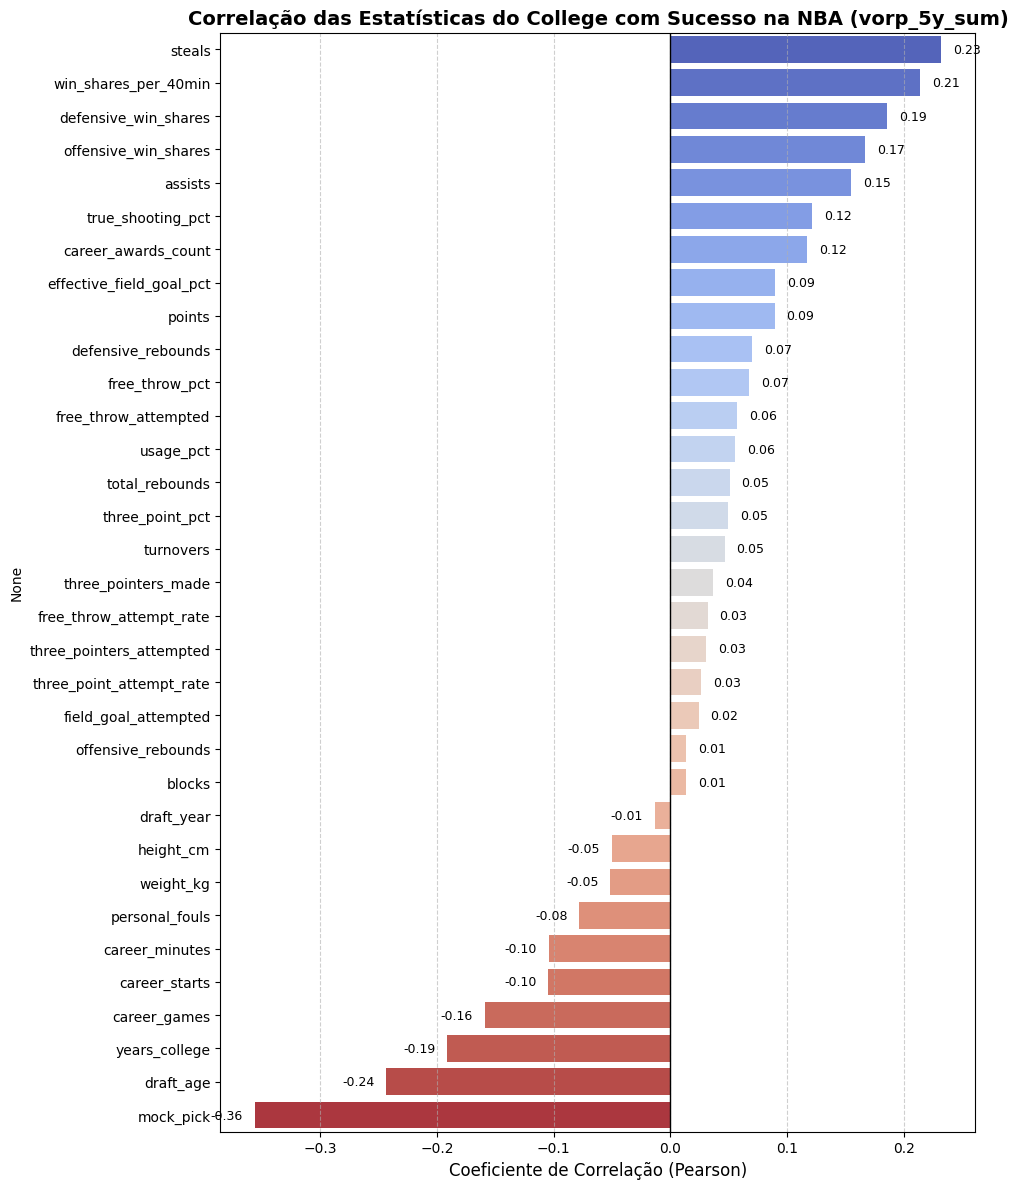

In [47]:
# 1. Definir o Alvo da Correlação
target_col = 'vorp_5y_sum'

# 2. Calcular a Correlação
# Criamos um dataframe temporário só com as features e o target
cols_to_analyze = quantitativas_features + [target_col]
corr_matrix = df_final_all_colluns[cols_to_analyze].corr()

# Pegamos apenas a coluna do target, removemos o próprio target (que seria 1.0) e ordenamos
target_corr = corr_matrix[target_col].drop(target_col).sort_values(ascending=False)

# 3. Gerar o Gráfico
plt.figure(figsize=(10, 12)) # Altura 12 para caber todas as variáveis

# Barplot
ax = sns.barplot(
    x=target_corr.values, 
    y=target_corr.index, 
    palette='coolwarm', # Azul = Correlação Positiva, Vermelho = Negativa
    hue=target_corr.index, # Para evitar o aviso de warning
    legend=False
)

# Estética
plt.title(f'Correlação das Estatísticas do College com Sucesso na NBA ({target_col})', fontsize=14, fontweight='bold')
plt.xlabel('Coeficiente de Correlação (Pearson)', fontsize=12)
plt.axvline(0, color='black', linewidth=1) # Linha preta no zero
plt.grid(axis='x', linestyle='--', alpha=0.6)

# Adicionar valores nas barras (Opcional, mas ajuda muito)
for i, v in enumerate(target_corr.values):
    # Ajusta a posição do texto baseado se o valor é positivo ou negativo
    offset = 0.01 if v >= 0 else -0.01
    ha = 'left' if v >= 0 else 'right'
    ax.text(v + offset, i, f'{v:.2f}', va='center', ha=ha, fontsize=9, color='black')

plt.tight_layout()
plt.show()

##### **Gráfico 3: Correlograma Relações entre Variáveis**

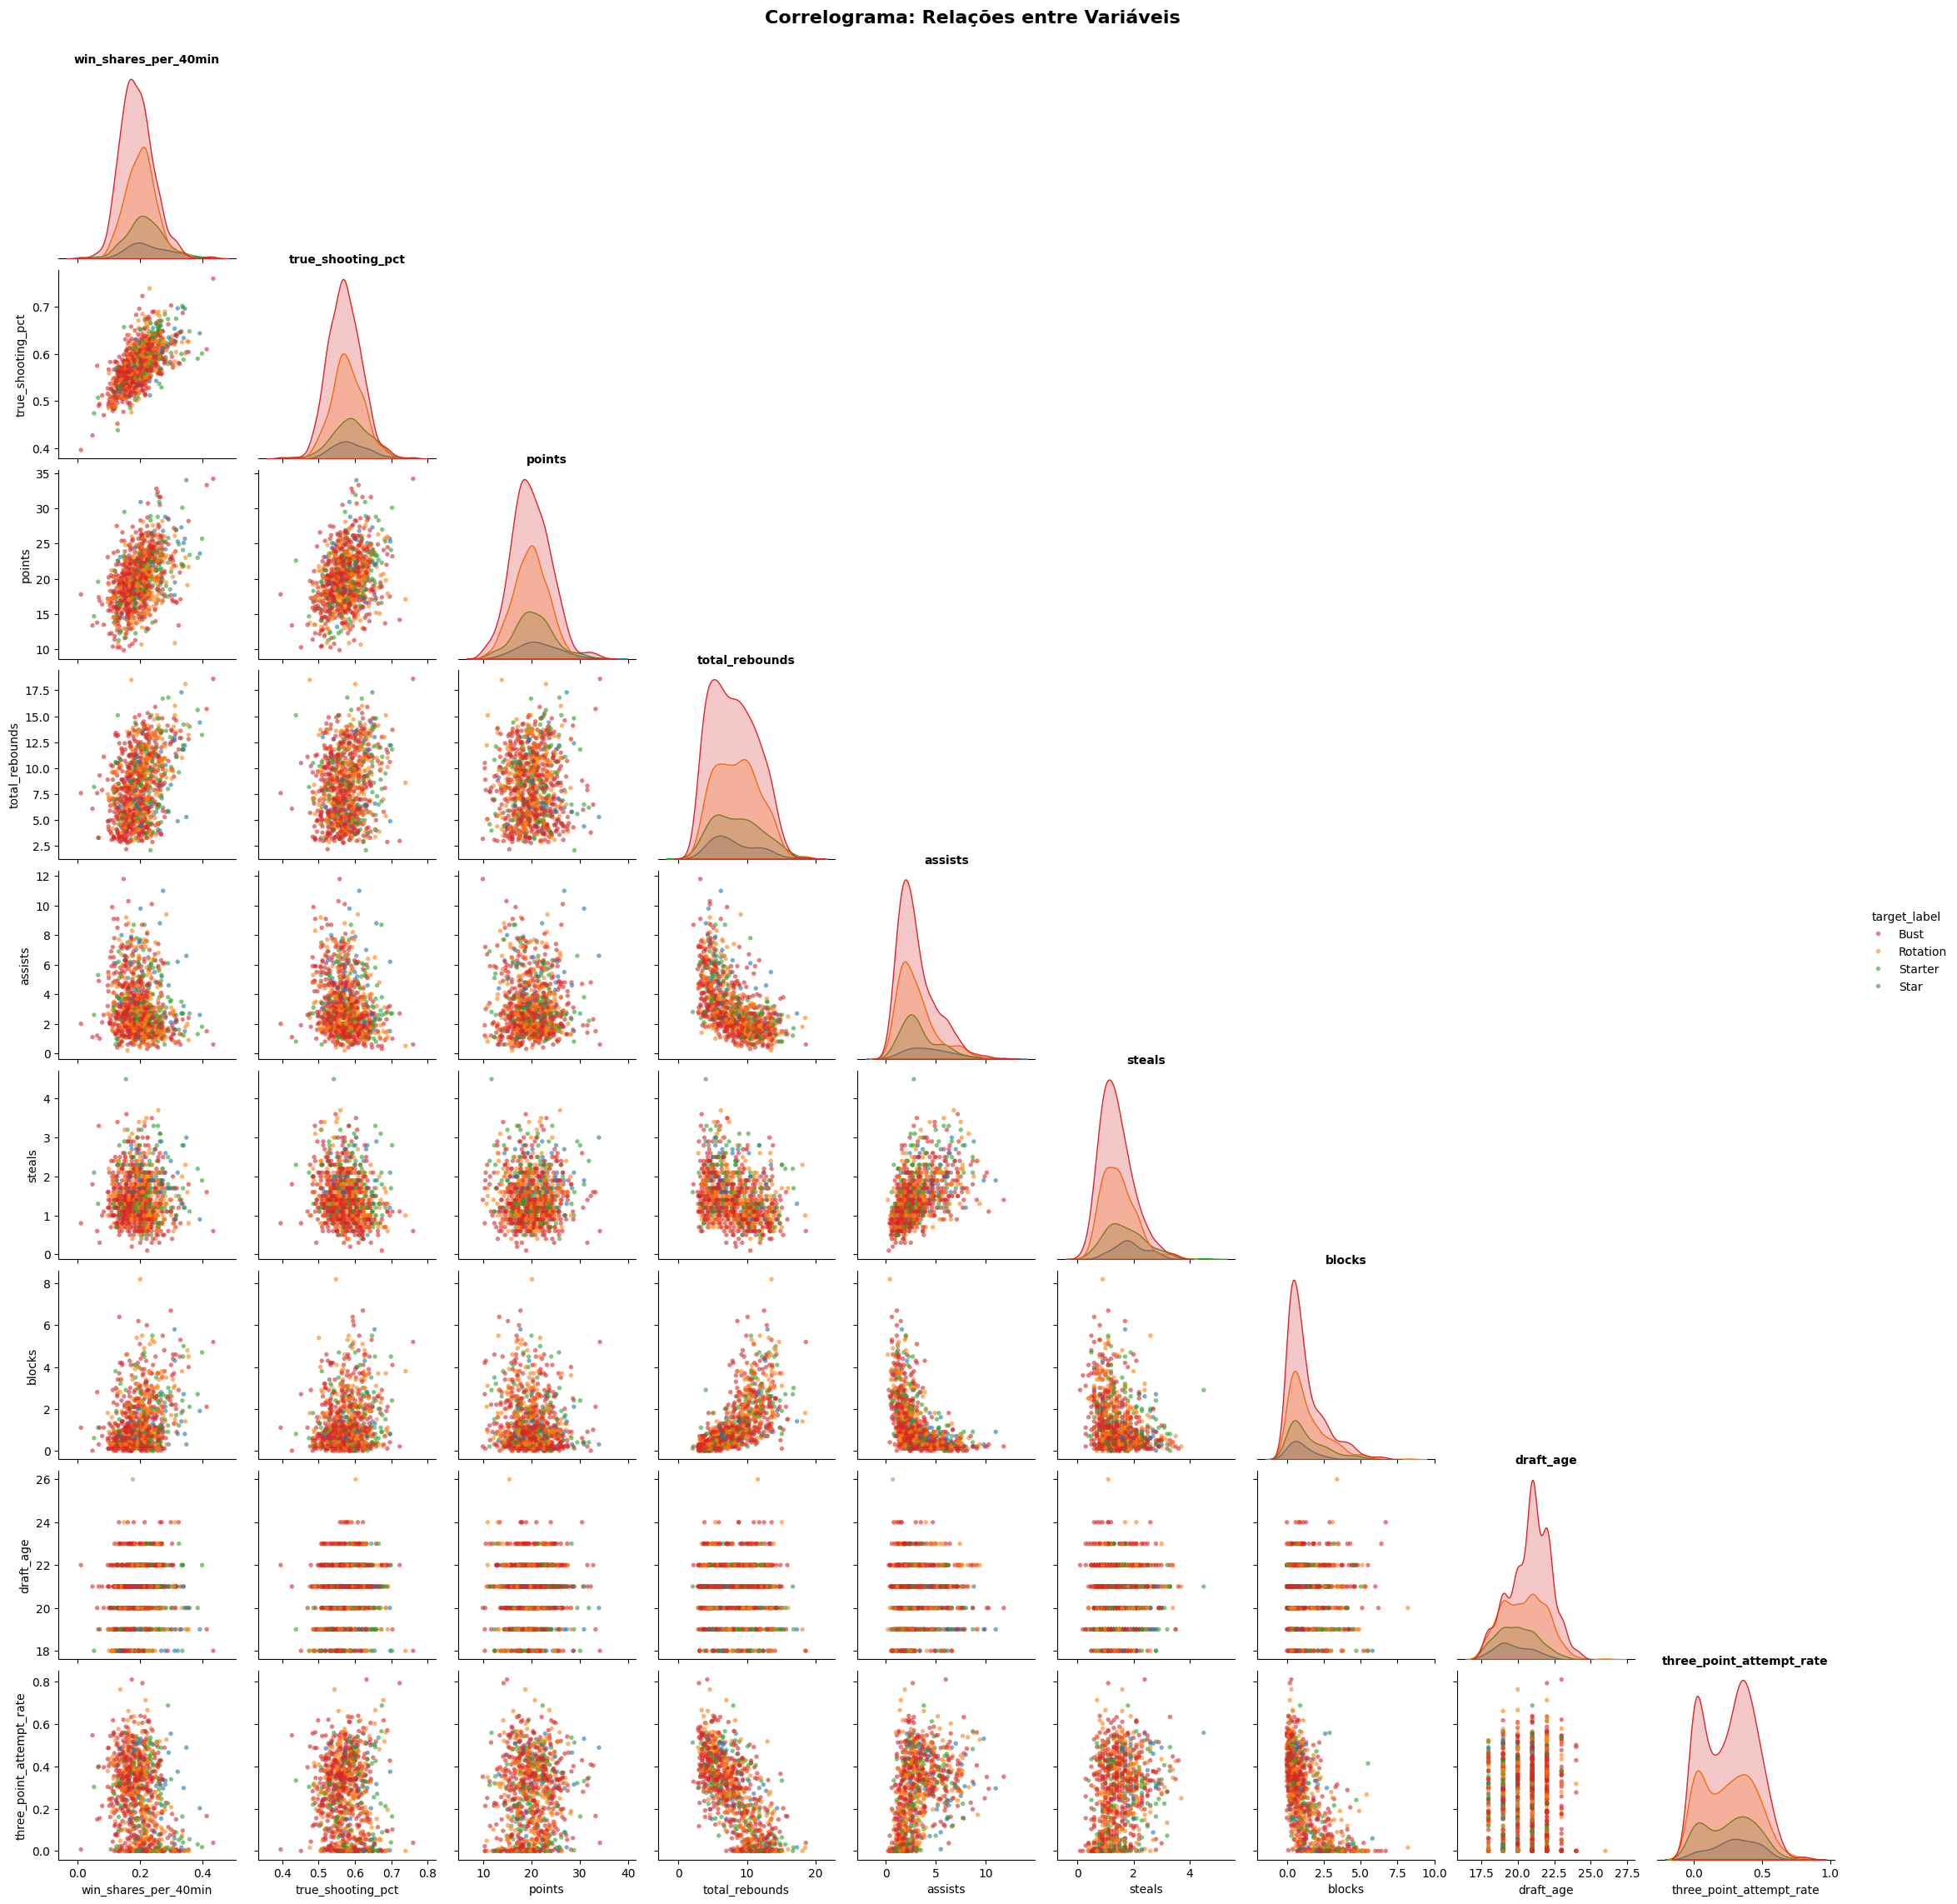

In [62]:
# 1. Gerar o Pairplot
g = sns.pairplot(
    data=df_final_all_colluns, 
    vars=quantitativas_features_eda, 
    hue='target_label', 
    hue_order=cols_order, 
    palette=palette_classes,
    corner=True,               
    diag_kind='kde',           
    height=2.5,                
    plot_kws={'alpha': 0.6, 's': 15, 'edgecolor': 'none'},
    diag_kws={'fill': True}
)

# 2. CORREÇÃO: Adicionar o nome da variável no topo dos gráficos da diagonal
# Percorremos os eixos da diagonal (g.diag_axes) e colocamos o título manualmente
for i, ax in enumerate(g.diag_axes):
    ax.set_title(quantitativas_features_eda[i], fontweight='bold', fontsize=10)

# Título Geral
g.fig.suptitle("Correlograma: Relações entre Variáveis", y=1.02, fontsize=16, fontweight='bold')

plt.show()

##### **Gráfico 4: Correlação entre Variáveis Quantitativas**

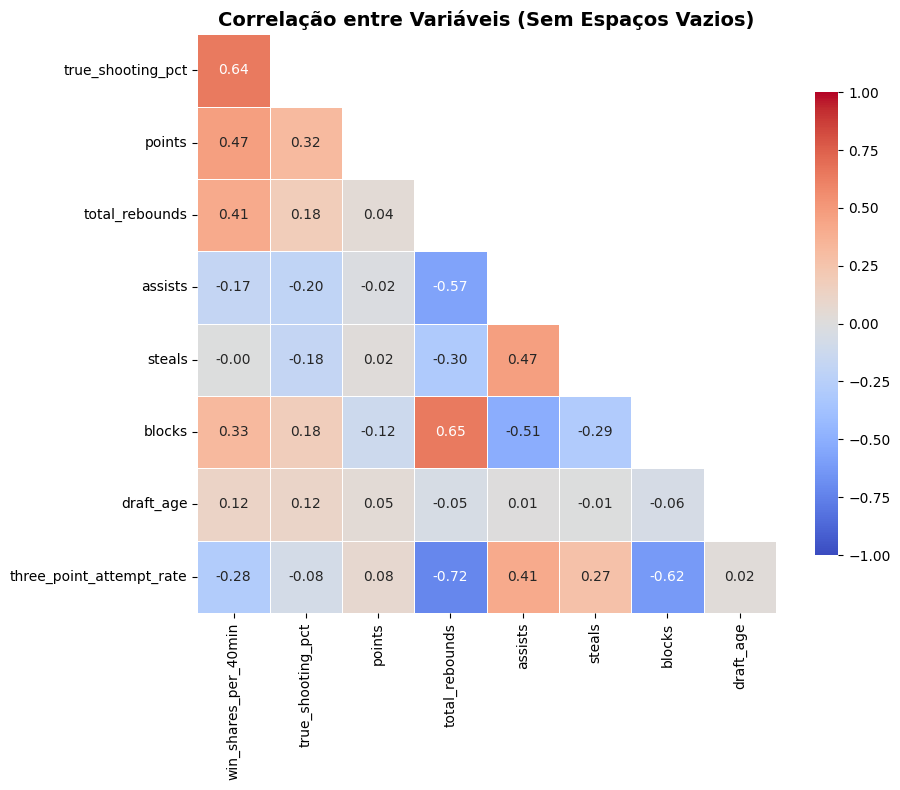

In [49]:
plt.figure(figsize=(10, 8))

# 1. Calcular a Correlação
corr_matrix = df_final_all_colluns[quantitativas_features_eda].corr()

# 2. Criar a Máscara Triangular
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# 3. Cortar Matriz e Máscara (O Pulo do Gato)
corr_matrix_cut = corr_matrix.iloc[1:, :-1]
mask_cut = mask[1:, :-1]

# 4. Plotar
sns.heatmap(
    corr_matrix_cut, 
    mask=mask_cut, 
    annot=True,      
    fmt=".2f",       
    cmap='coolwarm', 
    vmin=-1, vmax=1, 
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .8} 
)

plt.title('Correlação entre Variáveis (Sem Espaços Vazios)', fontsize=14, fontweight='bold')
plt.yticks(rotation=0) # Garante que os nomes no eixo Y fiquem retos
plt.tight_layout()
plt.show()

##### **Gráfico 5: Distribuição das Quantitativas**

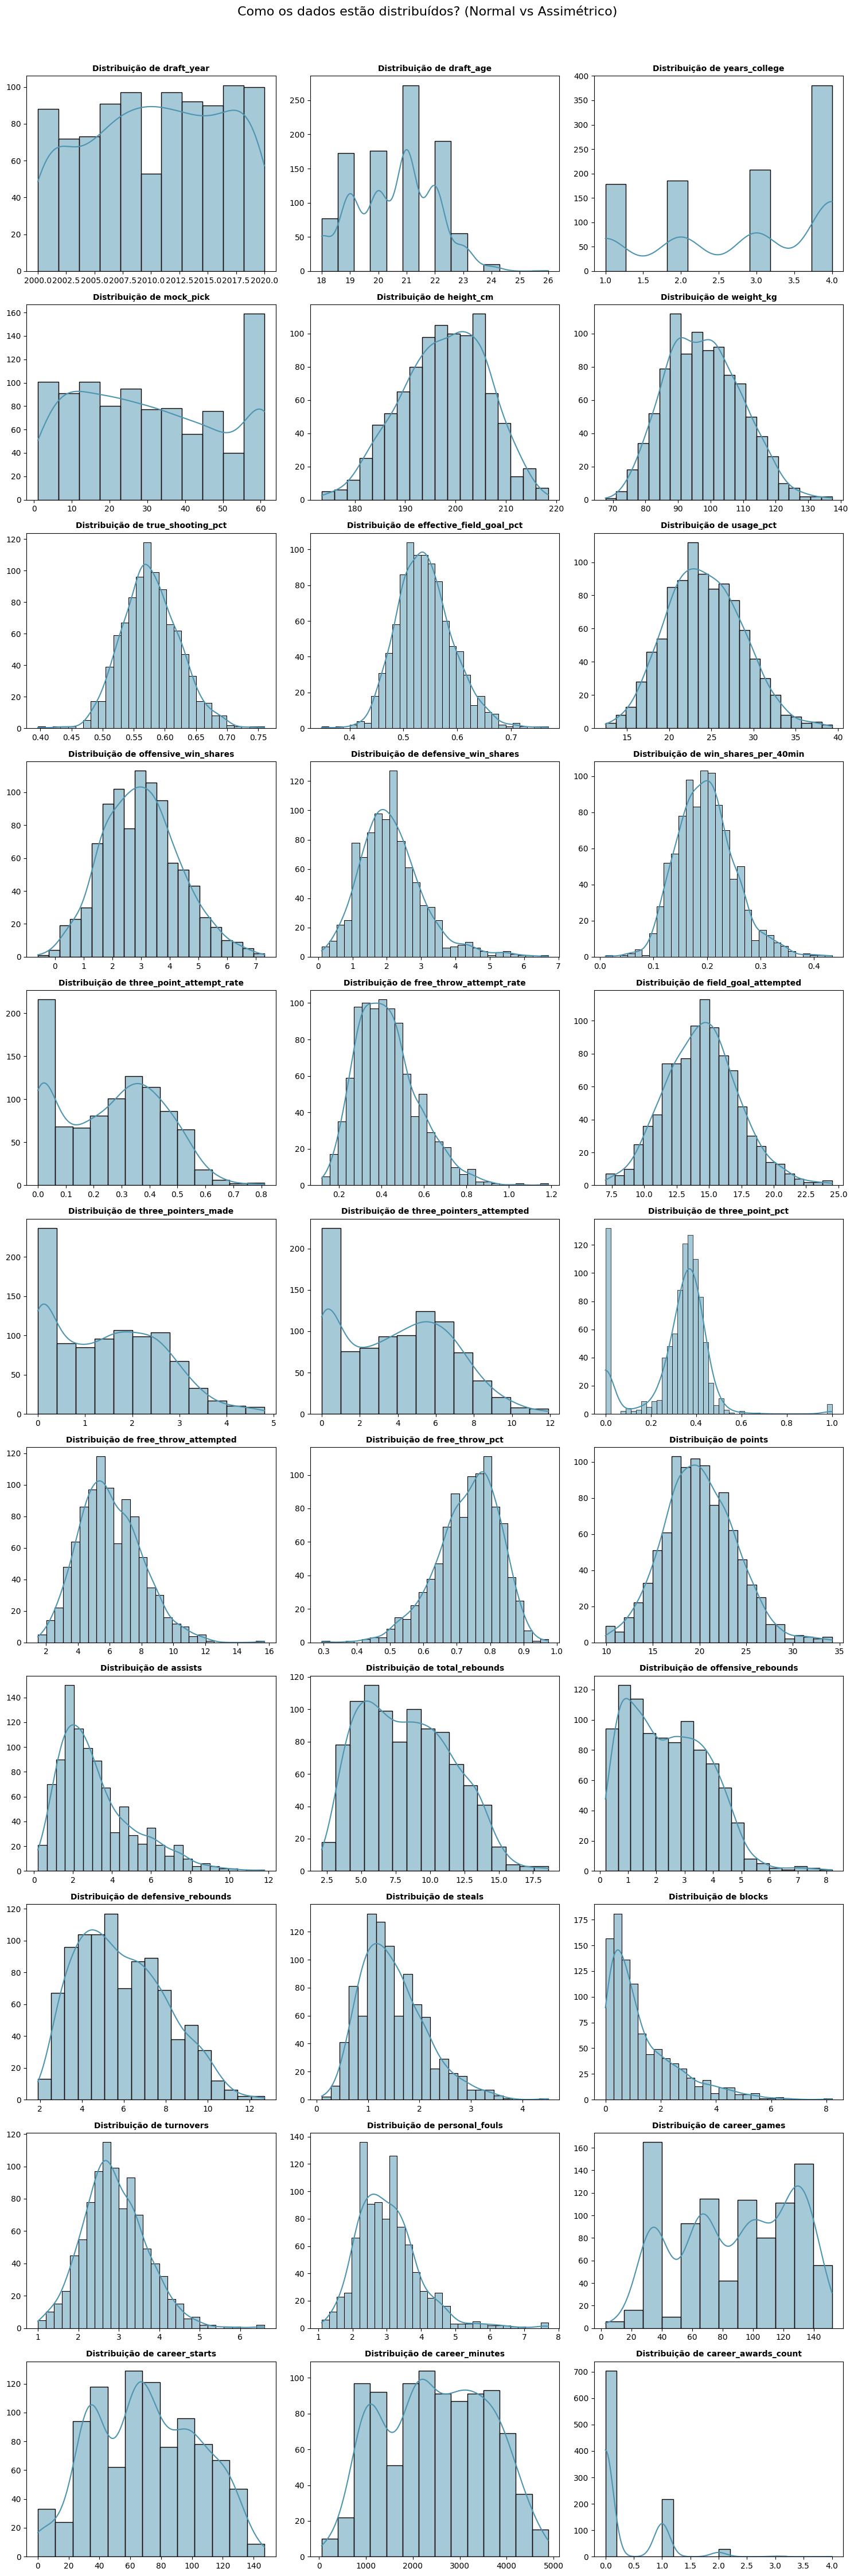

In [50]:
n = len(quantitativas_features)
ncols = 3
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows)) # Grid 3x3
axes = axes.flatten()

for i, col in enumerate(quantitativas_features):
    # Plota Histograma com linha de densidade (KDE)
    sns.histplot(data=df_final_all_colluns, x=col, kde=True, ax=axes[i], color="#4c94b0")
    axes[i].set_title(f'Distribuição de {col}', fontsize=10, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.suptitle('Como os dados estão distribuídos? (Normal vs Assimétrico)', y=1.02, fontsize=16)
plt.show()


#### **DEFINIÇÃO DAS VARIÁVEIS DO MODELO**

In [51]:
# ==============================================================================
# DEFINIÇÃO DAS VARIÁVEIS DO MODELO
# ==============================================================================

# 1. Variáveis Qualitativas (Categóricas)
# Estas precisarão de tratamento depois (One-Hot Encoding ou Label Encoding)
qualitativas = [
    'college_name', 
    'conference', 
    'position'
]

# 2. Variáveis Quantitativas (INPUTS / FEATURES - X)
# Estas são as colunas numéricas que o modelo vai ler para tentar prever o futuro.
quantitativas_features = [
    # --- Informações Físicas e do Draft ---
    'draft_year', 
    'draft_age', 
    'years_college', 
    'mock_pick',        # Expectativa do mercado antes do draft
    'height_cm', 
    'weight_kg',

    # --- Estatísticas Avançadas (Eficiência) ---
    'true_shooting_pct', 
    'effective_field_goal_pct', 
    'usage_pct',
    'offensive_win_shares', 
    'defensive_win_shares', 
    'win_shares_per_40min',
    'three_point_attempt_rate', 
    'free_throw_attempt_rate',

    # --- Estatísticas de Arremesso (Volume e Precisão) ---
    'field_goal_attempted', 
    'three_pointers_made', 
    'three_pointers_attempted', 
    'three_point_pct',
    'free_throw_attempted', 
    'free_throw_pct',

    # --- Estatísticas Tradicionais (Médias por Jogo) ---
    'points', 
    'assists', 
    'total_rebounds', 
    'offensive_rebounds', 
    'defensive_rebounds',
    'steals', 
    'blocks', 
    'turnovers', 
    'personal_fouls',

    # --- Experiência no College (Acumulados) ---
    'career_games', 
    'career_starts', 
    'career_minutes', 
    'career_awards_count'
]

# 3. Variáveis de Controle e Target (NÃO USAR NO TREINO)
# Identificadores, Targets e Data Leakage (dados do futuro da NBA)
variaveis_controle = [
    'player_id', 
    'player_name', 
    'target_class',          # O Y numérico (0, 1, 2, 3)
    'target_label',    # O Y em texto
    'vorp_5y_sum',     # Base do Target (Leakage)
    'seasons_played',  # Base do Target (Leakage)
    'draft_pick'       # O resultado real (não usar se quiser simular pre-draft)
]

# ==============================================================================
# VERIFICAÇÃO RÁPIDA
# ==============================================================================
print(f"Total de Features Quantitativas: {len(quantitativas_features)}")
print(f"Total de Features Qualitativas: {len(qualitativas)}")

Total de Features Quantitativas: 33
Total de Features Qualitativas: 3
